# Day 25 — Residual F3 Failure Decomposition

Decompose the residual F3 failure using source, class, and lexical evidence.

In [ ]:
# Imports
import json
from pathlib import Path

In [ ]:
# Project paths
def find_project_root():
    current = Path.cwd().resolve()
    for path in [current, *current.parents]:
        if (path / "README.md").exists():
            return path
    raise RuntimeError(
        "Project root not found. Run this notebook from inside the repository."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

def resolve_artifact_paths(value):
    """Rebase legacy project paths in loaded metadata; never rewrite artifacts.

    Keep all non-path values, model identifiers, and scientific settings intact.
    Support the original project name and the public repository name.
    """
    if isinstance(value, dict):
        return {key: resolve_artifact_paths(item) for key, item in value.items()}
    if isinstance(value, list):
        return [resolve_artifact_paths(item) for item in value]
    if isinstance(value, str):
        normalized = value.replace("\\", "/")
        for name in ("FinGPT_Project", "FinGPT-Temporal-Generalization"):
            marker = "/" + name + "/"
            if marker in normalized and "\n" not in normalized:
                # Only standalone filesystem references, never prose containing a path.
                prefix, relative = normalized.split(marker, 1)
                if prefix.startswith("/") or (len(prefix) > 1 and prefix[1] == ":"):
                    if not any(char.isspace() for char in relative):
                        return str(PROJECT_ROOT / relative)
    return value

def load_artifact_json(stream, *args, **kwargs):
    return resolve_artifact_paths(json.load(stream, *args, **kwargs))


In [ ]:
# Reproducibility settings
# Original seeds and deterministic settings remain at their original workflow
# positions below, including stage-specific RNG resets. No new seed is introduced.

## ColabFinGPT: Temporal Generalization of Financial LLMs under Distribution Shift

### Scientific Objective

Diagnose the residual **F3 positive-sentiment temporal failure** that persists after historical optimization.

Day 24 established that broad aggregate temporal degradation was largely repaired after adequate historical optimization, while F3 retained a localized class-specific failure characterized by:

- significantly lower Macro-F1 relative to Historical Validation;
- a substantial decline in positive-class recall;
- improved rather than degraded negative-class recall; and
- a dominant **positive → negative** error pathway.

Day 25 investigates whether this residual failure is associated with:

1. **class-prior / label-composition shift**;
2. **source-composition shift**;
3. **source-conditioned performance degradation**;
4. **lexical / topic shift**;
5. **a concentrated F3 positive-error cohort**; or
6. **a mixed source × lexical mechanism**.

### Scientific Firewall

Day 25 is a **mechanism-diagnosis day only**.

- No model retraining or fine-tuning.
- No LoRA updates.
- No checkpoint reselection.
- No hyperparameter search.
- No prompt modification.
- No parser or label-remapping changes.
- No threshold tuning.
- No new full-model inference.
- Frozen Day 24 predictions are the primary prediction artifact.
- Statistical analyses operate only on saved data and prediction artifacts.
- Association and concentration may be diagnosed; causal claims are not permitted without direct evidence.

### Primary Scientific Question

> **Why does F3 retain a directional positive → negative failure after the broader temporal degradation has been repaired?**

### Target Endpoint

Classify the residual F3 mechanism as one of:

- **A — primarily source-composition associated**
- **B — primarily lexical/topic associated**
- **C — mixed source + lexical association**
- **D — unresolved with current artifacts**

All conclusions must remain evidence-calibrated and reproducible.

In [2]:
# ============================================================
# DAY 25 — CELL 2
# PROJECT PATHS AND OUTPUT INITIALIZATION
# ============================================================

from pathlib import Path

# PROJECT_ROOT is discovered in the project-path setup cell.

DAY16_RESULTS_ROOT = PROJECT_ROOT / "results" / "day16"
DAY23_RESULTS_ROOT = PROJECT_ROOT / "results" / "day23"
DAY24_RESULTS_ROOT = PROJECT_ROOT / "results" / "day24"
DAY25_RESULTS_ROOT = PROJECT_ROOT / "results" / "day25"

NOTEBOOK_ROOT = PROJECT_ROOT / "notebooks"

# Create only the new Day25 output directory.
DAY25_RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
NOTEBOOK_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 120)
print("DAY 25 — PROJECT PATH INITIALIZATION")
print("=" * 120)

print(f"PROJECT_ROOT        : {PROJECT_ROOT}")
print(f"DAY16_RESULTS_ROOT  : {DAY16_RESULTS_ROOT}")
print(f"DAY23_RESULTS_ROOT  : {DAY23_RESULTS_ROOT}")
print(f"DAY24_RESULTS_ROOT  : {DAY24_RESULTS_ROOT}")
print(f"DAY25_RESULTS_ROOT  : {DAY25_RESULTS_ROOT}")
print(f"NOTEBOOK_ROOT       : {NOTEBOOK_ROOT}")

print("-" * 120)

print(f"Project exists      : {PROJECT_ROOT.exists()}")
print(f"Day16 exists        : {DAY16_RESULTS_ROOT.exists()}")
print(f"Day23 exists        : {DAY23_RESULTS_ROOT.exists()}")
print(f"Day24 exists        : {DAY24_RESULTS_ROOT.exists()}")
print(f"Day25 exists        : {DAY25_RESULTS_ROOT.exists()}")
print(f"Notebook root exists: {NOTEBOOK_ROOT.exists()}")

print("-" * 120)

required_upstream_dirs = {
    "PROJECT_ROOT": PROJECT_ROOT,
    "DAY16_RESULTS_ROOT": DAY16_RESULTS_ROOT,
    "DAY23_RESULTS_ROOT": DAY23_RESULTS_ROOT,
    "DAY24_RESULTS_ROOT": DAY24_RESULTS_ROOT,
}

missing_dirs = [
    name for name, path in required_upstream_dirs.items()
    if not path.exists()
]

if missing_dirs:
    raise FileNotFoundError(
        "Missing required upstream directories: "
        + ", ".join(missing_dirs)
    )

print("STATUS: PASS — Day25 project paths initialized.")
print("=" * 120)

DAY 25 — PROJECT PATH INITIALIZATION
PROJECT_ROOT        : /content/drive/MyDrive/FinGPT_Project
DAY16_RESULTS_ROOT  : /content/drive/MyDrive/FinGPT_Project/results/day16
DAY23_RESULTS_ROOT  : /content/drive/MyDrive/FinGPT_Project/results/day23
DAY24_RESULTS_ROOT  : /content/drive/MyDrive/FinGPT_Project/results/day24
DAY25_RESULTS_ROOT  : /content/drive/MyDrive/FinGPT_Project/results/day25
NOTEBOOK_ROOT       : /content/drive/MyDrive/FinGPT_Project/notebooks
------------------------------------------------------------------------------------------------------------------------
Project exists      : True
Day16 exists        : True
Day23 exists        : True
Day24 exists        : True
Day25 exists        : True
Notebook root exists: True
------------------------------------------------------------------------------------------------------------------------
STATUS: PASS — Day25 project paths initialized.


In [5]:
# ============================================================
# DAY 25 — CELL 4
# FROZEN FUTURE PREDICTION POPULATION INTEGRITY AUDIT
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Load frozen Day24 prediction artifact
# ------------------------------------------------------------

future_pred = pd.read_csv(
    DAY24_OPTIMIZED_FUTURE_PREDICTIONS
)

# ------------------------------------------------------------
# Basic structural audit
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — FROZEN FUTURE PREDICTION POPULATION INTEGRITY AUDIT")
print("=" * 120)

print(f"Artifact            : {DAY24_OPTIMIZED_FUTURE_PREDICTIONS}")
print(f"Rows                : {len(future_pred):,}")
print(f"Columns             : {future_pred.shape[1]}")
print("-" * 120)

print("COLUMN NAMES")
print("-" * 120)

for i, col in enumerate(future_pred.columns, start=1):
    print(f"{i:>3}. {col}")

print("-" * 120)

# ------------------------------------------------------------
# Identify canonical fields without silently guessing
# ------------------------------------------------------------

candidate_fields = {
    "observation_id": [
        "observation_id",
        "id",
        "row_id",
    ],
    "period": [
        "period",
        "window",
        "future_window",
    ],
    "true_label": [
        "true_label",
        "label",
        "gold_label",
    ],
    "predicted_label": [
        "predicted_label",
        "prediction",
        "pred_label",
    ],
    "prediction_valid": [
        "prediction_valid",
        "valid_prediction",
        "is_valid_prediction",
    ],
    "timestamp": [
        "timestamp",
        "datetime",
        "date",
        "published_at",
    ],
    "source": [
        "source",
        "publisher",
        "news_source",
    ],
    "text": [
        "text",
        "headline",
        "input",
        "news_text",
    ],
}

resolved_fields = {}

for semantic_name, candidates in candidate_fields.items():
    matches = [
        c for c in candidates
        if c in future_pred.columns
    ]

    if len(matches) == 1:
        resolved_fields[semantic_name] = matches[0]

    elif len(matches) > 1:
        resolved_fields[semantic_name] = matches

    else:
        resolved_fields[semantic_name] = None


print("RESOLVED / CANDIDATE SEMANTIC FIELDS")
print("-" * 120)

for semantic_name, resolved in resolved_fields.items():
    print(f"{semantic_name:<22}: {resolved}")

print("-" * 120)

# ------------------------------------------------------------
# Required population checks
# ------------------------------------------------------------

checks = {}

checks["n_rows_20002"] = len(future_pred) == 20002

obs_col = resolved_fields["observation_id"]
period_col = resolved_fields["period"]
true_col = resolved_fields["true_label"]
pred_col = resolved_fields["predicted_label"]
valid_col = resolved_fields["prediction_valid"]

# Do not proceed silently if any critical field is ambiguous.
critical_fields = {
    "observation_id": obs_col,
    "period": period_col,
    "true_label": true_col,
    "predicted_label": pred_col,
}

ambiguous_or_missing = {
    k: v
    for k, v in critical_fields.items()
    if (v is None or isinstance(v, list))
}

if ambiguous_or_missing:
    print("CRITICAL FIELD RESOLUTION REQUIRES REVIEW:")
    for k, v in ambiguous_or_missing.items():
        print(f"  {k}: {v}")
else:
    checks["observation_ids_nonmissing"] = (
        future_pred[obs_col].notna().all()
    )

    checks["observation_ids_unique"] = (
        future_pred[obs_col].nunique(dropna=False)
        == len(future_pred)
    )

    checks["true_labels_nonmissing"] = (
        future_pred[true_col].notna().all()
    )

    checks["predicted_labels_nonmissing"] = (
        future_pred[pred_col].notna().all()
    )

    observed_period_counts = (
        future_pred[period_col]
        .value_counts(dropna=False)
        .sort_index()
    )

    expected_period_counts = {
        "F1": 3602,
        "F2": 3522,
        "F3": 4818,
        "F4": 3872,
        "F5": 3588,
        "F6": 600,
    }

    checks["period_counts_exact"] = (
        observed_period_counts.to_dict()
        == expected_period_counts
    )

    checks["all_six_periods_present"] = (
        set(observed_period_counts.index.astype(str))
        == set(expected_period_counts.keys())
    )

    valid_labels = {
        "negative",
        "neutral",
        "positive",
    }

    checks["true_labels_valid"] = (
        set(
            future_pred[true_col]
            .astype(str)
            .str.lower()
            .unique()
        )
        <= valid_labels
    )

    checks["predicted_labels_valid"] = (
        set(
            future_pred[pred_col]
            .astype(str)
            .str.lower()
            .unique()
        )
        <= valid_labels
    )

    if (
        valid_col is not None
        and not isinstance(valid_col, list)
    ):
        valid_values = future_pred[valid_col]
        print(
            f"Prediction-valid field: {valid_col}"
        )
        print(
            f"Value counts          : "
            f"{valid_values.value_counts(dropna=False).to_dict()}"
        )


# ------------------------------------------------------------
# Display period counts and missingness
# ------------------------------------------------------------

if (
    period_col is not None
    and not isinstance(period_col, list)
):
    print("-" * 120)
    print("OBSERVED FUTURE WINDOW COUNTS")
    print("-" * 120)

    print(
        future_pred[period_col]
        .value_counts(dropna=False)
        .sort_index()
        .to_string()
    )

print("-" * 120)
print("MISSING VALUE COUNTS")
print("-" * 120)

missing_counts = (
    future_pred.isna()
    .sum()
    .sort_values(ascending=False)
)

print(
    missing_counts[
        missing_counts > 0
    ].to_string()
    if (missing_counts > 0).any()
    else "No missing values."
)

print("-" * 120)
print("INTEGRITY CHECKS")
print("-" * 120)

for name, passed in checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

print("-" * 120)

if checks and not all(checks.values()):
    raise AssertionError(
        "One or more frozen population integrity checks failed."
    )

if ambiguous_or_missing:
    print(
        "STATUS: REVIEW REQUIRED — population loaded, "
        "but one or more canonical field names require resolution."
    )
else:
    print(
        "STATUS: PASS — frozen Day24 Future population "
        "matches the expected Day25 analysis population."
    )

print("=" * 120)

DAY 25 — FROZEN FUTURE PREDICTION POPULATION INTEGRITY AUDIT
Artifact            : /content/drive/MyDrive/FinGPT_Project/results/day24/optimized_future_predictions.csv
Rows                : 20,002
Columns             : 12
------------------------------------------------------------------------------------------------------------------------
COLUMN NAMES
------------------------------------------------------------------------------------------------------------------------
  1. observation_id
  2. timestamp_utc
  3. period
  4. period_type
  5. source
  6. message_id
  7. text
  8. y_true
  9. y_pred_day24
 10. raw_generation_day24
 11. prediction_valid_day24
 12. inference_status_day24
------------------------------------------------------------------------------------------------------------------------
RESOLVED / CANDIDATE SEMANTIC FIELDS
------------------------------------------------------------------------------------------------------------------------
observation_id        : ob

In [6]:
# ============================================================
# DAY 25 — CELL 5
# CANONICAL ANALYSIS SCHEMA FREEZE
# ============================================================

# ------------------------------------------------------------
# Freeze exact Day24 column identities for Day25
# ------------------------------------------------------------

DAY25_COLS = {
    "observation_id": "observation_id",
    "timestamp": "timestamp_utc",
    "period": "period",
    "period_type": "period_type",
    "source": "source",
    "message_id": "message_id",
    "text": "text",
    "true_label": "y_true",
    "predicted_label": "y_pred_day24",
    "raw_generation": "raw_generation_day24",
    "prediction_valid": "prediction_valid_day24",
    "inference_status": "inference_status_day24",
}

required_columns = list(DAY25_COLS.values())

missing_required_columns = [
    col
    for col in required_columns
    if col not in future_pred.columns
]

if missing_required_columns:
    raise KeyError(
        "Missing required Day25 columns: "
        + ", ".join(missing_required_columns)
    )

# ------------------------------------------------------------
# Create canonical Day25 analysis view
# ------------------------------------------------------------

day25_future = future_pred[
    required_columns
].copy()

day25_future = day25_future.rename(
    columns={
        DAY25_COLS["observation_id"]: "observation_id",
        DAY25_COLS["timestamp"]: "timestamp",
        DAY25_COLS["period"]: "period",
        DAY25_COLS["period_type"]: "period_type",
        DAY25_COLS["source"]: "source",
        DAY25_COLS["message_id"]: "message_id",
        DAY25_COLS["text"]: "text",
        DAY25_COLS["true_label"]: "true_label",
        DAY25_COLS["predicted_label"]: "predicted_label",
        DAY25_COLS["raw_generation"]: "raw_generation",
        DAY25_COLS["prediction_valid"]: "prediction_valid",
        DAY25_COLS["inference_status"]: "inference_status",
    }
)

# Normalize only categorical label casing.
day25_future["true_label"] = (
    day25_future["true_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

day25_future["predicted_label"] = (
    day25_future["predicted_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# ------------------------------------------------------------
# Formal integrity checks
# ------------------------------------------------------------

expected_period_counts = {
    "F1": 3602,
    "F2": 3522,
    "F3": 4818,
    "F4": 3872,
    "F5": 3588,
    "F6": 600,
}

valid_labels = {
    "negative",
    "neutral",
    "positive",
}

checks = {
    "n_rows_20002":
        len(day25_future) == 20002,

    "observation_ids_nonmissing":
        day25_future["observation_id"].notna().all(),

    "observation_ids_unique":
        day25_future["observation_id"].is_unique,

    "period_counts_exact":
        day25_future["period"]
        .value_counts()
        .sort_index()
        .to_dict()
        == expected_period_counts,

    "true_labels_valid":
        set(day25_future["true_label"].unique())
        <= valid_labels,

    "predicted_labels_valid":
        set(day25_future["predicted_label"].unique())
        <= valid_labels,

    "prediction_valid_nonmissing":
        day25_future["prediction_valid"].notna().all(),

    "source_nonmissing":
        day25_future["source"].notna().all(),

    "text_nonmissing":
        day25_future["text"].notna().all(),

    "timestamp_nonmissing":
        day25_future["timestamp"].notna().all(),
}

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — CANONICAL ANALYSIS SCHEMA FREEZE")
print("=" * 120)

print(f"Rows                : {len(day25_future):,}")
print(f"Columns             : {day25_future.shape[1]}")

print("-" * 120)
print("CANONICAL COLUMN MAPPING")
print("-" * 120)

for semantic_name, original_name in DAY25_COLS.items():
    print(
        f"{semantic_name:<22} <- {original_name}"
    )

print("-" * 120)
print("LABEL VALUES")
print("-" * 120)

print(
    "True labels       :",
    sorted(day25_future["true_label"].unique())
)

print(
    "Predicted labels  :",
    sorted(day25_future["predicted_label"].unique())
)

print("-" * 120)
print("PREDICTION VALIDITY")
print("-" * 120)

print(
    day25_future["prediction_valid"]
    .value_counts(dropna=False)
    .to_string()
)

print("-" * 120)
print("INFERENCE STATUS")
print("-" * 120)

print(
    day25_future["inference_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("-" * 120)
print("FORMAL INTEGRITY CHECKS")
print("-" * 120)

for name, passed in checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(checks.values()):
    failed = [
        name
        for name, passed in checks.items()
        if not passed
    ]

    raise AssertionError(
        "Day25 canonical schema integrity failure: "
        + ", ".join(failed)
    )

print("-" * 120)
print(
    "STATUS: PASS — canonical Day25 Future analysis "
    "population frozen."
)
print("=" * 120)

DAY 25 — CANONICAL ANALYSIS SCHEMA FREEZE
Rows                : 20,002
Columns             : 12
------------------------------------------------------------------------------------------------------------------------
CANONICAL COLUMN MAPPING
------------------------------------------------------------------------------------------------------------------------
observation_id         <- observation_id
timestamp              <- timestamp_utc
period                 <- period
period_type            <- period_type
source                 <- source
message_id             <- message_id
text                   <- text
true_label             <- y_true
predicted_label        <- y_pred_day24
raw_generation         <- raw_generation_day24
prediction_valid       <- prediction_valid_day24
inference_status       <- inference_status_day24
------------------------------------------------------------------------------------------------------------------------
LABEL VALUES
---------------------------------

In [7]:
# ============================================================
# DAY 25 — CELL 6
# DAY25 ANALYSIS MANIFEST FREEZE
# ============================================================

import json
import hashlib
from datetime import datetime, timezone

# ------------------------------------------------------------
# Stable ordered observation-ID hash
# ------------------------------------------------------------

ordered_observation_ids = (
    day25_future["observation_id"]
    .astype(str)
    .tolist()
)

ordered_observation_id_sha256 = hashlib.sha256(
    "\n".join(ordered_observation_ids).encode("utf-8")
).hexdigest()

# ------------------------------------------------------------
# Frozen upstream artifact hashes
# ------------------------------------------------------------

upstream_hashes = {
    "optimized_future_predictions_sha256":
        sha256_file(DAY24_OPTIMIZED_FUTURE_PREDICTIONS),

    "optimized_future_prediction_manifest_sha256":
        sha256_file(DAY24_OPTIMIZED_FUTURE_MANIFEST),

    "day24_completion_checkpoint_sha256":
        sha256_file(DAY24_COMPLETION_CHECKPOINT),

    "future_window_metrics_sha256":
        sha256_file(DAY24_FUTURE_WINDOW_METRICS),

    "bootstrap_delta_vs_validation_ci_sha256":
        sha256_file(DAY24_BOOTSTRAP_DELTA_VS_VALIDATION),

    "day24_final_scientific_summary_sha256":
        sha256_file(DAY24_FINAL_SCIENTIFIC_SUMMARY),
}

# ------------------------------------------------------------
# Frozen population summaries
# ------------------------------------------------------------

period_counts = {
    str(k): int(v)
    for k, v in (
        day25_future["period"]
        .value_counts()
        .sort_index()
        .items()
    )
}

true_label_counts = {
    str(k): int(v)
    for k, v in (
        day25_future["true_label"]
        .value_counts()
        .sort_index()
        .items()
    )
}

predicted_label_counts = {
    str(k): int(v)
    for k, v in (
        day25_future["predicted_label"]
        .value_counts()
        .sort_index()
        .items()
    )
}

source_count = int(
    day25_future["source"].nunique()
)

timestamp_min = str(
    day25_future["timestamp"].min()
)

timestamp_max = str(
    day25_future["timestamp"].max()
)

# ------------------------------------------------------------
# Build canonical Day25 manifest
# ------------------------------------------------------------

day25_analysis_manifest = {
    "day": 25,

    "artifact": "day25_analysis_manifest",

    "status": "INITIALIZED_AND_FROZEN",

    "scientific_objective": (
        "Diagnose the residual F3 positive-sentiment "
        "temporal failure that persists after historical optimization."
    ),

    "primary_question": (
        "Is the residual F3 positive-to-negative failure associated "
        "with class-prior shift, source composition, lexical/topic "
        "shift, a concentrated error cohort, or a mixed mechanism?"
    ),

    "scientific_firewall": {
        "model_retraining": False,
        "lora_updates": False,
        "checkpoint_reselection": False,
        "hyperparameter_search": False,
        "prompt_modification": False,
        "parser_modification": False,
        "label_remapping": False,
        "threshold_tuning": False,
        "new_full_model_inference": False,
        "causal_claims_without_direct_evidence": False,
    },

    "primary_prediction_artifact": {
        "path": str(
            DAY24_OPTIMIZED_FUTURE_PREDICTIONS
        ),
        "sha256": upstream_hashes[
            "optimized_future_predictions_sha256"
        ],
        "immutable": True,
        "day24_manifest_status":
            day24_prediction_manifest.get(
                "status"
            ),
        "day24_completion_status":
            day24_completion.get(
                "status"
            ),
        "day24_scientific_status":
            day24_completion.get(
                "scientific_status"
            ),
    },

    "population_identity": {
        "n": int(len(day25_future)),
        "ordered_observation_id_sha256":
            ordered_observation_id_sha256,
        "observation_ids_unique":
            bool(
                day25_future[
                    "observation_id"
                ].is_unique
            ),
        "period_counts":
            period_counts,
        "true_label_counts":
            true_label_counts,
        "predicted_label_counts":
            predicted_label_counts,
        "n_sources":
            source_count,
        "timestamp_min":
            timestamp_min,
        "timestamp_max":
            timestamp_max,
        "prediction_valid_count":
            int(
                day25_future[
                    "prediction_valid"
                ].sum()
            ),
        "inference_success_count":
            int(
                (
                    day25_future[
                        "inference_status"
                    ] == "success"
                ).sum()
            ),
    },

    "canonical_schema": {
        "observation_id":
            "observation_id",
        "timestamp":
            "timestamp",
        "period":
            "period",
        "period_type":
            "period_type",
        "source":
            "source",
        "message_id":
            "message_id",
        "text":
            "text",
        "true_label":
            "true_label",
        "predicted_label":
            "predicted_label",
        "raw_generation":
            "raw_generation",
        "prediction_valid":
            "prediction_valid",
        "inference_status":
            "inference_status",
    },

    "upstream_artifact_hashes":
        upstream_hashes,

    "planned_mechanism_classes": {
        "A": (
            "primarily source-composition associated"
        ),
        "B": (
            "primarily lexical/topic associated "
            "and persists within sources"
        ),
        "C": (
            "mixed source + lexical association"
        ),
        "D": (
            "unresolved with current artifacts"
        ),
    },

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}

# ------------------------------------------------------------
# Save manifest
# ------------------------------------------------------------

DAY25_ANALYSIS_MANIFEST_PATH = (
    DAY25_RESULTS_ROOT
    / "day25_analysis_manifest.json"
)

with open(
    DAY25_ANALYSIS_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        day25_analysis_manifest,
        f,
        indent=2,
        ensure_ascii=False,
    )

# ------------------------------------------------------------
# Reload and verify persisted artifact
# ------------------------------------------------------------

with open(
    DAY25_ANALYSIS_MANIFEST_PATH,
    "r",
    encoding="utf-8",
) as f:
    manifest_check = load_artifact_json(f)

manifest_checks = {
    "manifest_exists":
        DAY25_ANALYSIS_MANIFEST_PATH.exists(),

    "manifest_nonempty":
        DAY25_ANALYSIS_MANIFEST_PATH.stat().st_size > 0,

    "day_is_25":
        manifest_check["day"] == 25,

    "population_n_20002":
        manifest_check[
            "population_identity"
        ]["n"] == 20002,

    "day24_prediction_hash_exact":
        manifest_check[
            "primary_prediction_artifact"
        ]["sha256"]
        == current_prediction_sha256,

    "day24_status_pass":
        manifest_check[
            "primary_prediction_artifact"
        ]["day24_completion_status"]
        == "PASS",

    "day24_scientific_complete":
        manifest_check[
            "primary_prediction_artifact"
        ]["day24_scientific_status"]
        == "COMPLETE",

    "no_new_inference_allowed":
        manifest_check[
            "scientific_firewall"
        ]["new_full_model_inference"]
        is False,
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — ANALYSIS MANIFEST FREEZE")
print("=" * 120)

print(
    f"Saved manifest       : "
    f"{DAY25_ANALYSIS_MANIFEST_PATH}"
)

print(
    f"Manifest size        : "
    f"{DAY25_ANALYSIS_MANIFEST_PATH.stat().st_size:,} bytes"
)

print(
    f"Manifest SHA256      : "
    f"{sha256_file(DAY25_ANALYSIS_MANIFEST_PATH)}"
)

print("-" * 120)
print("FROZEN POPULATION IDENTITY")
print("-" * 120)

print(
    f"Observations         : "
    f"{len(day25_future):,}"
)

print(
    f"Ordered ID SHA256    : "
    f"{ordered_observation_id_sha256}"
)

print(
    f"Unique sources       : "
    f"{source_count}"
)

print(
    f"Timestamp range      : "
    f"{timestamp_min} -> {timestamp_max}"
)

print(
    f"Period counts        : "
    f"{period_counts}"
)

print(
    f"True label counts    : "
    f"{true_label_counts}"
)

print(
    f"Predicted counts     : "
    f"{predicted_label_counts}"
)

print("-" * 120)
print("FROZEN DAY24 PREDICTION IDENTITY")
print("-" * 120)

print(
    upstream_hashes[
        "optimized_future_predictions_sha256"
    ]
)

print("-" * 120)
print("MANIFEST INTEGRITY CHECKS")
print("-" * 120)

for name, passed in manifest_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(manifest_checks.values()):
    failed = [
        name
        for name, passed
        in manifest_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Day25 analysis manifest freeze failed: "
        + ", ".join(failed)
    )

print("-" * 120)
print(
    "STATUS: PASS — Day25 analysis identity, "
    "population, schema, and scientific firewall frozen."
)
print("=" * 120)

DAY 25 — ANALYSIS MANIFEST FREEZE
Saved manifest       : /content/drive/MyDrive/FinGPT_Project/results/day25/day25_analysis_manifest.json
Manifest size        : 3,375 bytes
Manifest SHA256      : fb7143c351faa58a2699e17a1f3132517d8ec019444cbda643f9af4d774b4051
------------------------------------------------------------------------------------------------------------------------
FROZEN POPULATION IDENTITY
------------------------------------------------------------------------------------------------------------------------
Observations         : 20,002
Ordered ID SHA256    : f4aa6032db13ff333af6f0580286b1ef0d20ec44d2aa0117b6860eb58be56c51
Unique sources       : 8
Timestamp range      : 2026-01-01 04:05:22+00:00 -> 2026-06-05 12:59:13+00:00
Period counts        : {'F1': 3602, 'F2': 3522, 'F3': 4818, 'F4': 3872, 'F5': 3588, 'F6': 600}
True label counts    : {'negative': 5203, 'neutral': 11748, 'positive': 3051}
Predicted counts     : {'negative': 5044, 'neutral': 11807, 'positive': 3151

## Stage 1 — Label-Composition / Prior-Shift Audit

### Scientific Question

Is F3 unusual because its true-label composition or predicted-label composition differs materially from Historical Validation and neighboring Future periods?

The analysis will compare:

- true-label counts and proportions;
- positive-class prevalence;
- predicted-label composition;
- absolute percentage-point shifts;
- F3 versus Historical Validation;
- F3 versus neighboring periods F2 and F4.

A class-prior shift may contribute to aggregate metric changes, but it cannot by itself explain a collapse in recall conditional on the true positive class. Therefore, this stage is diagnostic rather than sufficient for mechanism attribution.

Before computing the comparison, the exact frozen Historical Validation population must be recovered from the Day23 artifacts.

In [9]:
# ============================================================
# DAY 25 — CELL 7
# HISTORICAL VALIDATION PREDICTION ARTIFACT AUDIT
# ============================================================

import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Canonical Day23 Historical Validation artifact
# ------------------------------------------------------------

DAY23_HISTVAL_ROOT = (
    DAY23_RESULTS_ROOT
    / "final_historical_validation"
)

DAY23_HISTVAL_PREDICTIONS = (
    DAY23_HISTVAL_ROOT
    / "final_historical_validation_predictions.csv"
)

if not DAY23_HISTVAL_PREDICTIONS.exists():
    raise FileNotFoundError(
        f"Historical Validation prediction artifact not found: "
        f"{DAY23_HISTVAL_PREDICTIONS}"
    )

# ------------------------------------------------------------
# Load artifact
# ------------------------------------------------------------

histval_pred = pd.read_csv(
    DAY23_HISTVAL_PREDICTIONS
)

# ------------------------------------------------------------
# Structural audit
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — HISTORICAL VALIDATION PREDICTION ARTIFACT AUDIT")
print("=" * 120)

print(
    f"Artifact            : "
    f"{DAY23_HISTVAL_PREDICTIONS}"
)

print(
    f"Rows                : "
    f"{len(histval_pred):,}"
)

print(
    f"Columns             : "
    f"{histval_pred.shape[1]}"
)

print("-" * 120)
print("COLUMN NAMES")
print("-" * 120)

for i, col in enumerate(
    histval_pred.columns,
    start=1,
):
    print(
        f"{i:>3}. {col}"
    )

print("-" * 120)
print("MISSING VALUE COUNTS")
print("-" * 120)

missing_counts = (
    histval_pred
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

if (missing_counts > 0).any():
    print(
        missing_counts[
            missing_counts > 0
        ].to_string()
    )
else:
    print(
        "No missing values."
    )

print("-" * 120)
print("BASIC UNIQUENESS / VALUE AUDIT")
print("-" * 120)

# Candidate ID fields
for candidate in [
    "observation_id",
    "id",
    "row_id",
]:
    if candidate in histval_pred.columns:
        print(
            f"{candidate:<24}: "
            f"nunique={histval_pred[candidate].nunique(dropna=False):,}"
        )

# Candidate label fields
for candidate in [
    "y_true",
    "true_label",
    "label",
    "gold_label",
]:
    if candidate in histval_pred.columns:
        print(
            f"{candidate:<24}: "
            f"{histval_pred[candidate].value_counts(dropna=False).to_dict()}"
        )

# Candidate prediction fields
for candidate in [
    "y_pred_day23",
    "y_pred",
    "predicted_label",
    "prediction",
]:
    if candidate in histval_pred.columns:
        print(
            f"{candidate:<24}: "
            f"{histval_pred[candidate].value_counts(dropna=False).to_dict()}"
        )

print("-" * 120)
print("DAY25-REQUIRED COMPOSITION FIELDS")
print("-" * 120)

required_semantic_candidates = {
    "observation_id": [
        "observation_id",
        "id",
        "row_id",
    ],
    "timestamp": [
        "timestamp_utc",
        "timestamp",
        "datetime",
        "date",
    ],
    "source": [
        "source",
        "publisher",
        "news_source",
    ],
    "text": [
        "text",
        "headline",
        "input",
        "news_text",
    ],
    "true_label": [
        "y_true",
        "true_label",
        "label",
    ],
    "predicted_label": [
        "y_pred_day23",
        "y_pred",
        "predicted_label",
        "prediction",
    ],
}

resolved_histval_fields = {}

for semantic_name, candidates in (
    required_semantic_candidates.items()
):
    matches = [
        c
        for c in candidates
        if c in histval_pred.columns
    ]

    if len(matches) == 1:
        resolved_histval_fields[
            semantic_name
        ] = matches[0]

    elif len(matches) > 1:
        resolved_histval_fields[
            semantic_name
        ] = matches

    else:
        resolved_histval_fields[
            semantic_name
        ] = None

for semantic_name, resolved in (
    resolved_histval_fields.items()
):
    print(
        f"{semantic_name:<22}: "
        f"{resolved}"
    )

print("-" * 120)

critical_missing = {
    k: v
    for k, v in (
        resolved_histval_fields.items()
    )
    if (
        k in {
            "observation_id",
            "true_label",
            "predicted_label",
        }
        and (
            v is None
            or isinstance(v, list)
        )
    )
}

composition_missing = {
    k: v
    for k, v in (
        resolved_histval_fields.items()
    )
    if (
        k in {
            "timestamp",
            "source",
            "text",
        }
        and (
            v is None
            or isinstance(v, list)
        )
    )
}

if critical_missing:
    print(
        "STATUS: REVIEW REQUIRED — "
        "critical Historical Validation fields "
        "need resolution."
    )

elif composition_missing:
    print(
        "STATUS: PARTIAL — Historical Validation "
        "predictions are usable for performance, "
        "but composition fields require upstream enrichment."
    )

else:
    print(
        "STATUS: PASS — Historical Validation "
        "prediction artifact contains all fields "
        "required for Day25 composition and lexical analyses."
    )

print("=" * 120)

DAY 25 — HISTORICAL VALIDATION PREDICTION ARTIFACT AUDIT
Artifact            : /content/drive/MyDrive/FinGPT_Project/results/day23/final_historical_validation/final_historical_validation_predictions.csv
Rows                : 5,859
Columns             : 6
------------------------------------------------------------------------------------------------------------------------
COLUMN NAMES
------------------------------------------------------------------------------------------------------------------------
  1. observation_id
  2. date
  3. source
  4. true_label
  5. predicted_label
  6. raw_generation
------------------------------------------------------------------------------------------------------------------------
MISSING VALUE COUNTS
------------------------------------------------------------------------------------------------------------------------
No missing values.
-------------------------------------------------------------------------------------------------------------

In [11]:
# ============================================================
# DAY 25 — TEMPORARY CHECK CELL
# IDENTIFY CANONICAL UPSTREAM HISTORICAL VALIDATION TEXT SOURCE
# ============================================================

import pandas as pd

DAY07_CLEAN = (
    PROJECT_ROOT
    / "results"
    / "day07"
    / "temporal_dataset_clean.csv"
)

DAY07_SPLIT = (
    PROJECT_ROOT
    / "results"
    / "day07"
    / "temporal_split.csv"
)

candidate_upstream_files = {
    "day07_temporal_dataset_clean": DAY07_CLEAN,
    "day07_temporal_split": DAY07_SPLIT,
}

histval_ids = set(
    histval_pred["observation_id"]
    .astype(str)
)

print("=" * 120)
print("DAY 25 — CANONICAL UPSTREAM TEXT SOURCE AUDIT")
print("=" * 120)

for name, path in candidate_upstream_files.items():

    print(f"\n[{name}]")
    print("-" * 120)

    if not path.exists():
        print("STATUS: MISSING")
        continue

    df = pd.read_csv(path)

    print(f"Path                : {path}")
    print(f"Rows                : {len(df):,}")
    print(f"Columns             : {df.shape[1]}")
    print(
        "Column names        : "
        + ", ".join(df.columns.astype(str))
    )

    # --------------------------------------------------------
    # Identify likely fields
    # --------------------------------------------------------

    id_candidates = [
        c for c in [
            "observation_id",
            "id",
            "row_id",
        ]
        if c in df.columns
    ]

    text_candidates = [
        c for c in [
            "text",
            "headline",
            "message",
            "input",
            "news_text",
        ]
        if c in df.columns
    ]

    source_candidates = [
        c for c in [
            "source",
            "publisher",
            "news_source",
        ]
        if c in df.columns
    ]

    label_candidates = [
        c for c in [
            "label",
            "true_label",
            "y_true",
            "sentiment",
        ]
        if c in df.columns
    ]

    split_candidates = [
        c for c in [
            "split",
            "temporal_split",
            "set",
            "partition",
            "period",
        ]
        if c in df.columns
    ]

    print(f"ID candidates       : {id_candidates}")
    print(f"Text candidates     : {text_candidates}")
    print(f"Source candidates   : {source_candidates}")
    print(f"Label candidates    : {label_candidates}")
    print(f"Split candidates    : {split_candidates}")

    # --------------------------------------------------------
    # Exact Historical Validation ID coverage
    # --------------------------------------------------------

    if len(id_candidates) == 1:

        id_col = id_candidates[0]

        upstream_ids = set(
            df[id_col]
            .astype(str)
        )

        matched_ids = (
            histval_ids
            & upstream_ids
        )

        print(
            f"Historical V IDs matched : "
            f"{len(matched_ids):,} / {len(histval_ids):,}"
        )

        print(
            f"Exact V ID coverage      : "
            f"{len(matched_ids) == len(histval_ids)}"
        )

        print(
            f"Upstream IDs unique      : "
            f"{df[id_col].astype(str).is_unique}"
        )

    else:
        print(
            "Historical V ID coverage  : "
            "cannot evaluate unambiguously"
        )

    # --------------------------------------------------------
    # Missingness in likely text field
    # --------------------------------------------------------

    if len(text_candidates) == 1:
        text_col = text_candidates[0]

        print(
            f"Text missing count       : "
            f"{df[text_col].isna().sum():,}"
        )

    print("-" * 120)

print("=" * 120)
print(
    "TEMPORARY AUDIT COMPLETE — choose the upstream source "
    "only after exact Historical Validation ID coverage is verified."
)
print("=" * 120)

DAY 25 — CANONICAL UPSTREAM TEXT SOURCE AUDIT

[day07_temporal_dataset_clean]
------------------------------------------------------------------------------------------------------------------------
Path                : /content/drive/MyDrive/FinGPT_Project/results/day07/temporal_dataset_clean.csv
Rows                : 39,965
Columns             : 10
Column names        : message_id, channel_username, date, text, views, forwards, sentiment, reason, year, year_month
ID candidates       : []
Text candidates     : ['text']
Source candidates   : []
Label candidates    : ['sentiment']
Split candidates    : []
Historical V ID coverage  : cannot evaluate unambiguously
Text missing count       : 0
------------------------------------------------------------------------------------------------------------------------

[day07_temporal_split]
------------------------------------------------------------------------------------------------------------------------
Path                : /content/dri

In [12]:
# ============================================================
# DAY 25 — CELL 8
# HISTORICAL VALIDATION CORE POPULATION FREEZE
# ============================================================

import hashlib

# ------------------------------------------------------------
# Freeze the exact Day23 Historical Validation population
# ------------------------------------------------------------

required_histval_columns = [
    "observation_id",
    "date",
    "source",
    "true_label",
    "predicted_label",
    "raw_generation",
]

missing_histval_columns = [
    col
    for col in required_histval_columns
    if col not in histval_pred.columns
]

if missing_histval_columns:
    raise KeyError(
        "Missing required Historical Validation columns: "
        + ", ".join(missing_histval_columns)
    )

day25_validation = (
    histval_pred[
        required_histval_columns
    ]
    .copy()
    .rename(
        columns={
            "date": "timestamp",
        }
    )
)

# ------------------------------------------------------------
# Normalize categorical labels only
# ------------------------------------------------------------

day25_validation["true_label"] = (
    day25_validation["true_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

day25_validation["predicted_label"] = (
    day25_validation["predicted_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Freeze period identity
day25_validation["period"] = "V"

# ------------------------------------------------------------
# Ordered Historical Validation ID hash
# ------------------------------------------------------------

validation_ordered_ids = (
    day25_validation["observation_id"]
    .astype(str)
    .tolist()
)

validation_ordered_id_sha256 = hashlib.sha256(
    "\n".join(validation_ordered_ids)
    .encode("utf-8")
).hexdigest()

# ------------------------------------------------------------
# Formal integrity checks
# ------------------------------------------------------------

valid_labels = {
    "negative",
    "neutral",
    "positive",
}

validation_checks = {
    "n_rows_5859":
        len(day25_validation) == 5859,

    "observation_ids_nonmissing":
        day25_validation[
            "observation_id"
        ].notna().all(),

    "observation_ids_unique":
        day25_validation[
            "observation_id"
        ].is_unique,

    "timestamp_nonmissing":
        day25_validation[
            "timestamp"
        ].notna().all(),

    "source_nonmissing":
        day25_validation[
            "source"
        ].notna().all(),

    "true_labels_nonmissing":
        day25_validation[
            "true_label"
        ].notna().all(),

    "predicted_labels_nonmissing":
        day25_validation[
            "predicted_label"
        ].notna().all(),

    "true_labels_valid":
        set(
            day25_validation[
                "true_label"
            ].unique()
        ) <= valid_labels,

    "predicted_labels_valid":
        set(
            day25_validation[
                "predicted_label"
            ].unique()
        ) <= valid_labels,

    "period_is_validation":
        (
            day25_validation["period"]
            == "V"
        ).all(),
}

# ------------------------------------------------------------
# Summaries
# ------------------------------------------------------------

true_counts_v = (
    day25_validation["true_label"]
    .value_counts()
    .sort_index()
)

pred_counts_v = (
    day25_validation["predicted_label"]
    .value_counts()
    .sort_index()
)

source_counts_v = (
    day25_validation["source"]
    .value_counts()
)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — HISTORICAL VALIDATION CORE POPULATION FREEZE")
print("=" * 120)

print(
    f"Artifact            : "
    f"{DAY23_HISTVAL_PREDICTIONS}"
)

print(
    f"Rows                : "
    f"{len(day25_validation):,}"
)

print(
    f"Unique sources      : "
    f"{day25_validation['source'].nunique():,}"
)

print(
    f"Ordered ID SHA256   : "
    f"{validation_ordered_id_sha256}"
)

print("-" * 120)
print("TRUE LABEL COUNTS")
print("-" * 120)

print(
    true_counts_v.to_string()
)

print("-" * 120)
print("PREDICTED LABEL COUNTS")
print("-" * 120)

print(
    pred_counts_v.to_string()
)

print("-" * 120)
print("SOURCE COUNTS")
print("-" * 120)

print(
    source_counts_v.to_string()
)

print("-" * 120)
print("INTEGRITY CHECKS")
print("-" * 120)

for name, passed in validation_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(validation_checks.values()):

    failed = [
        name
        for name, passed
        in validation_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Historical Validation population freeze failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    "NOTE: Historical Validation text is not required "
    "for Stage 1–3 and will be enriched separately "
    "before Stage 5 lexical analysis."
)

print(
    "STATUS: PASS — exact Day23 Historical Validation "
    "core population frozen for Day25."
)

print("=" * 120)

DAY 25 — HISTORICAL VALIDATION CORE POPULATION FREEZE
Artifact            : /content/drive/MyDrive/FinGPT_Project/results/day23/final_historical_validation/final_historical_validation_predictions.csv
Rows                : 5,859
Unique sources      : 7
Ordered ID SHA256   : 09ccb61d3ae6cc4e384c7fe5364043a5f7806ca31ee72830324d149f573748bf
------------------------------------------------------------------------------------------------------------------------
TRUE LABEL COUNTS
------------------------------------------------------------------------------------------------------------------------
true_label
negative    1132
neutral     3687
positive    1040
------------------------------------------------------------------------------------------------------------------------
PREDICTED LABEL COUNTS
------------------------------------------------------------------------------------------------------------------------
predicted_label
negative    1072
neutral     3642
positive    1145
-------

In [13]:
# ============================================================
# DAY 25 — CELL 9
# LABEL / PREDICTION COMPOSITION BY PERIOD
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Build unified V + F1–F6 composition population
# ------------------------------------------------------------

validation_composition = (
    day25_validation[
        [
            "observation_id",
            "period",
            "true_label",
            "predicted_label",
        ]
    ]
    .copy()
)

future_composition = (
    day25_future[
        [
            "observation_id",
            "period",
            "true_label",
            "predicted_label",
        ]
    ]
    .copy()
)

composition_population = pd.concat(
    [
        validation_composition,
        future_composition,
    ],
    axis=0,
    ignore_index=True,
)

period_order = [
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

label_order = [
    "negative",
    "neutral",
    "positive",
]

# ------------------------------------------------------------
# True-label composition
# ------------------------------------------------------------

true_rows = []

for period in period_order:

    df_p = composition_population[
        composition_population["period"] == period
    ]

    n_period = len(df_p)

    for label in label_order:

        count = int(
            (df_p["true_label"] == label).sum()
        )

        proportion = (
            count / n_period
            if n_period > 0
            else np.nan
        )

        true_rows.append(
            {
                "period": period,
                "label": label,
                "count": count,
                "period_n": n_period,
                "proportion": proportion,
                "percentage": proportion * 100,
            }
        )

label_composition = pd.DataFrame(
    true_rows
)

# ------------------------------------------------------------
# Predicted-label composition
# ------------------------------------------------------------

pred_rows = []

for period in period_order:

    df_p = composition_population[
        composition_population["period"] == period
    ]

    n_period = len(df_p)

    for label in label_order:

        count = int(
            (df_p["predicted_label"] == label).sum()
        )

        proportion = (
            count / n_period
            if n_period > 0
            else np.nan
        )

        pred_rows.append(
            {
                "period": period,
                "label": label,
                "count": count,
                "period_n": n_period,
                "proportion": proportion,
                "percentage": proportion * 100,
            }
        )

prediction_composition = pd.DataFrame(
    pred_rows
)

# ------------------------------------------------------------
# Positive prevalence summary
# ------------------------------------------------------------

positive_prevalence = (
    label_composition[
        label_composition["label"] == "positive"
    ][
        [
            "period",
            "count",
            "period_n",
            "proportion",
            "percentage",
        ]
    ]
    .copy()
    .rename(
        columns={
            "count": "positive_count",
            "proportion": "positive_prevalence",
            "percentage": "positive_prevalence_pct",
        }
    )
)

# ------------------------------------------------------------
# Formal checks
# ------------------------------------------------------------

expected_period_n = {
    "V": 5859,
    "F1": 3602,
    "F2": 3522,
    "F3": 4818,
    "F4": 3872,
    "F5": 3588,
    "F6": 600,
}

composition_checks = {}

for period, expected_n in expected_period_n.items():

    true_period = label_composition[
        label_composition["period"] == period
    ]

    pred_period = prediction_composition[
        prediction_composition["period"] == period
    ]

    composition_checks[
        f"{period}_true_count_sum"
    ] = (
        int(true_period["count"].sum())
        == expected_n
    )

    composition_checks[
        f"{period}_pred_count_sum"
    ] = (
        int(pred_period["count"].sum())
        == expected_n
    )

    composition_checks[
        f"{period}_true_prop_sum"
    ] = np.isclose(
        true_period["proportion"].sum(),
        1.0,
    )

    composition_checks[
        f"{period}_pred_prop_sum"
    ] = np.isclose(
        pred_period["proportion"].sum(),
        1.0,
    )

# ------------------------------------------------------------
# Save canonical Stage 1 artifacts
# ------------------------------------------------------------

LABEL_COMPOSITION_PATH = (
    DAY25_RESULTS_ROOT
    / "label_composition_by_period.csv"
)

PREDICTION_COMPOSITION_PATH = (
    DAY25_RESULTS_ROOT
    / "prediction_composition_by_period.csv"
)

POSITIVE_PREVALENCE_PATH = (
    DAY25_RESULTS_ROOT
    / "positive_prevalence_by_period.csv"
)

label_composition.to_csv(
    LABEL_COMPOSITION_PATH,
    index=False,
)

prediction_composition.to_csv(
    PREDICTION_COMPOSITION_PATH,
    index=False,
)

positive_prevalence.to_csv(
    POSITIVE_PREVALENCE_PATH,
    index=False,
)

# ------------------------------------------------------------
# Display compact tables
# ------------------------------------------------------------

true_display = (
    label_composition
    .pivot(
        index="period",
        columns="label",
        values="percentage",
    )
    .reindex(
        index=period_order,
        columns=label_order,
    )
)

pred_display = (
    prediction_composition
    .pivot(
        index="period",
        columns="label",
        values="percentage",
    )
    .reindex(
        index=period_order,
        columns=label_order,
    )
)

print("=" * 120)
print("DAY 25 — LABEL / PREDICTION COMPOSITION BY PERIOD")
print("=" * 120)

print("TRUE-LABEL COMPOSITION (%)")
print("-" * 120)

print(
    true_display
    .round(2)
    .to_string()
)

print("-" * 120)
print("PREDICTED-LABEL COMPOSITION (%)")
print("-" * 120)

print(
    pred_display
    .round(2)
    .to_string()
)

print("-" * 120)
print("POSITIVE PREVALENCE")
print("-" * 120)

print(
    positive_prevalence[
        [
            "period",
            "positive_count",
            "period_n",
            "positive_prevalence_pct",
        ]
    ]
    .round(
        {
            "positive_prevalence_pct": 2
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("COMPOSITION INTEGRITY CHECKS")
print("-" * 120)

for name, passed in composition_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    composition_checks.values()
):

    failed = [
        name
        for name, passed
        in composition_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Stage 1 composition integrity failure: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: {LABEL_COMPOSITION_PATH}"
)

print(
    f"Saved: {PREDICTION_COMPOSITION_PATH}"
)

print(
    f"Saved: {POSITIVE_PREVALENCE_PATH}"
)

print("-" * 120)

print(
    "STATUS: PASS — V and F1–F6 label / prediction "
    "composition tables constructed and saved."
)

print("=" * 120)

DAY 25 — LABEL / PREDICTION COMPOSITION BY PERIOD
TRUE-LABEL COMPOSITION (%)
------------------------------------------------------------------------------------------------------------------------
label   negative  neutral  positive
period                             
V          19.32    62.93     17.75
F1         18.85    63.52     17.63
F2         22.03    60.76     17.21
F3         36.01    52.70     11.29
F4         26.76    57.31     15.93
F5         23.38    61.71     14.91
F6         23.00    58.00     19.00
------------------------------------------------------------------------------------------------------------------------
PREDICTED-LABEL COMPOSITION (%)
------------------------------------------------------------------------------------------------------------------------
label   negative  neutral  positive
period                             
V          18.30    62.16     19.54
F1         17.55    63.99     18.46
F2         21.32    59.91     18.77
F3         35.51    53.7

In [14]:
# ============================================================
# DAY 25 — CELL 10
# F3 CLASS-PRIOR SHIFT QUANTIFICATION
# ============================================================

comparison_periods = [
    "V",
    "F2",
    "F4",
]

f3_prior_rows = []

for reference_period in comparison_periods:

    for label in label_order:

        f3_true = label_composition[
            (label_composition["period"] == "F3")
            & (label_composition["label"] == label)
        ].iloc[0]

        ref_true = label_composition[
            (label_composition["period"] == reference_period)
            & (label_composition["label"] == label)
        ].iloc[0]

        f3_pred = prediction_composition[
            (prediction_composition["period"] == "F3")
            & (prediction_composition["label"] == label)
        ].iloc[0]

        ref_pred = prediction_composition[
            (prediction_composition["period"] == reference_period)
            & (prediction_composition["label"] == label)
        ].iloc[0]

        f3_prior_rows.append(
            {
                "reference_period": reference_period,
                "label": label,

                "reference_true_pct":
                    float(ref_true["percentage"]),

                "f3_true_pct":
                    float(f3_true["percentage"]),

                "true_shift_pp":
                    float(
                        f3_true["percentage"]
                        - ref_true["percentage"]
                    ),

                "reference_pred_pct":
                    float(ref_pred["percentage"]),

                "f3_pred_pct":
                    float(f3_pred["percentage"]),

                "pred_shift_pp":
                    float(
                        f3_pred["percentage"]
                        - ref_pred["percentage"]
                    ),
            }
        )

f3_prior_shift = pd.DataFrame(
    f3_prior_rows
)

# ------------------------------------------------------------
# Positive-specific summary
# ------------------------------------------------------------

positive_shift_summary = (
    f3_prior_shift[
        f3_prior_shift["label"] == "positive"
    ][
        [
            "reference_period",
            "reference_true_pct",
            "f3_true_pct",
            "true_shift_pp",
            "reference_pred_pct",
            "f3_pred_pct",
            "pred_shift_pp",
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# Save evidence table
# ------------------------------------------------------------

F3_PRIOR_SHIFT_PATH = (
    DAY25_RESULTS_ROOT
    / "f3_prior_shift_vs_reference.csv"
)

f3_prior_shift.to_csv(
    F3_PRIOR_SHIFT_PATH,
    index=False,
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — F3 CLASS-PRIOR SHIFT QUANTIFICATION")
print("=" * 120)

print("TRUE / PREDICTED COMPOSITION SHIFTS (percentage points)")
print("-" * 120)

display_cols = [
    "reference_period",
    "label",
    "reference_true_pct",
    "f3_true_pct",
    "true_shift_pp",
    "reference_pred_pct",
    "f3_pred_pct",
    "pred_shift_pp",
]

print(
    f3_prior_shift[
        display_cols
    ]
    .round(2)
    .to_string(
        index=False
    )
)

print("-" * 120)
print("POSITIVE-CLASS PRIOR SHIFT")
print("-" * 120)

print(
    positive_shift_summary
    .round(2)
    .to_string(
        index=False
    )
)

# ------------------------------------------------------------
# Stage 1 descriptive interpretation
# ------------------------------------------------------------

f3_positive_true_pct = float(
    label_composition[
        (label_composition["period"] == "F3")
        & (label_composition["label"] == "positive")
    ]["percentage"].iloc[0]
)

f3_negative_true_pct = float(
    label_composition[
        (label_composition["period"] == "F3")
        & (label_composition["label"] == "negative")
    ]["percentage"].iloc[0]
)

v_positive_true_pct = float(
    label_composition[
        (label_composition["period"] == "V")
        & (label_composition["label"] == "positive")
    ]["percentage"].iloc[0]
)

v_negative_true_pct = float(
    label_composition[
        (label_composition["period"] == "V")
        & (label_composition["label"] == "negative")
    ]["percentage"].iloc[0]
)

positive_shift_vs_v = (
    f3_positive_true_pct
    - v_positive_true_pct
)

negative_shift_vs_v = (
    f3_negative_true_pct
    - v_negative_true_pct
)

print("-" * 120)
print("STAGE 1 SCIENTIFIC READOUT")
print("-" * 120)

print(
    f"F3 positive prevalence vs V : "
    f"{positive_shift_vs_v:+.2f} pp"
)

print(
    f"F3 negative prevalence vs V : "
    f"{negative_shift_vs_v:+.2f} pp"
)

print(
    "Interpretation              : "
    "F3 exhibits a material class-prior shift."
)

print(
    "Limitation                  : "
    "This composition shift can affect aggregate metrics, "
    "but cannot by itself explain the previously established "
    "within-positive recall collapse."
)

print("-" * 120)
print(
    f"Saved: {F3_PRIOR_SHIFT_PATH}"
)

print(
    "STATUS: PASS — F3 class-prior shift quantified."
)

print("=" * 120)

DAY 25 — F3 CLASS-PRIOR SHIFT QUANTIFICATION
TRUE / PREDICTED COMPOSITION SHIFTS (percentage points)
------------------------------------------------------------------------------------------------------------------------
reference_period    label  reference_true_pct  f3_true_pct  true_shift_pp  reference_pred_pct  f3_pred_pct  pred_shift_pp
               V negative               19.32        36.01          16.69               18.30        35.51          17.22
               V  neutral               62.93        52.70         -10.23               62.16        53.74          -8.42
               V positive               17.75        11.29          -6.46               19.54        10.75          -8.79
              F2 negative               22.03        36.01          13.98               21.32        35.51          14.19
              F2  neutral               60.76        52.70          -8.06               59.91        53.74          -6.17
              F2 positive               17.21 

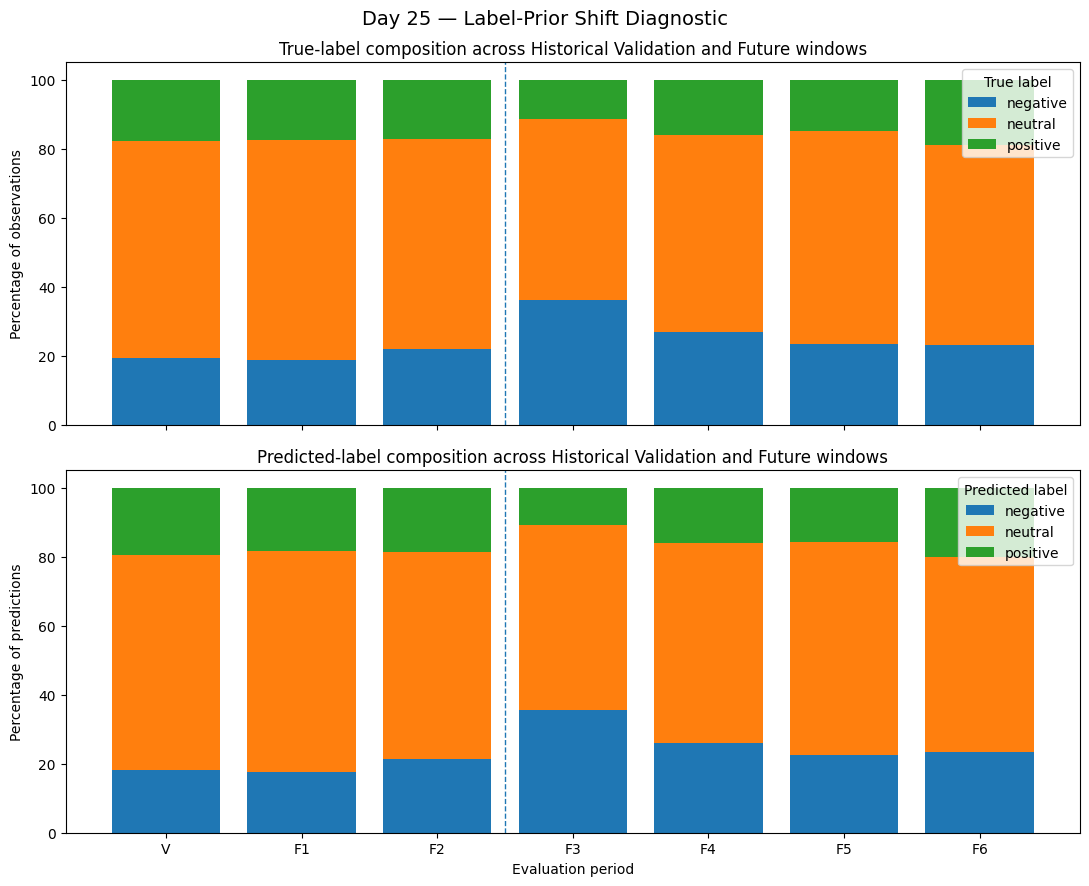

DAY 25 — STAGE 1 FIGURE SAVE
Saved figure : /content/drive/MyDrive/FinGPT_Project/results/day25/label_prior_shift.png
Size         : 147,283 bytes
------------------------------------------------------------------------------------------------------------------------
PASS   — figure_exists
PASS   — figure_nonempty
------------------------------------------------------------------------------------------------------------------------
STATUS: PASS — Stage 1 label-prior diagnostic figure saved.


In [15]:
# ============================================================
# DAY 25 — CELL 11
# STAGE 1 LABEL-PRIOR SHIFT FIGURE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Prepare matrices
# ------------------------------------------------------------

true_plot = (
    label_composition
    .pivot(
        index="period",
        columns="label",
        values="percentage",
    )
    .reindex(
        index=period_order,
        columns=label_order,
    )
)

pred_plot = (
    prediction_composition
    .pivot(
        index="period",
        columns="label",
        values="percentage",
    )
    .reindex(
        index=period_order,
        columns=label_order,
    )
)

x = np.arange(len(period_order))

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 9),
    sharex=True,
)

# True-label composition
bottom = np.zeros(len(period_order))

for label in label_order:

    values = true_plot[label].values

    axes[0].bar(
        x,
        values,
        bottom=bottom,
        label=label,
    )

    bottom += values

axes[0].set_ylabel(
    "Percentage of observations"
)

axes[0].set_title(
    "True-label composition across Historical Validation and Future windows"
)

axes[0].legend(
    title="True label",
    loc="upper right",
)

axes[0].axvline(
    2.5,
    linestyle="--",
    linewidth=1,
)

# Predicted-label composition
bottom = np.zeros(len(period_order))

for label in label_order:

    values = pred_plot[label].values

    axes[1].bar(
        x,
        values,
        bottom=bottom,
        label=label,
    )

    bottom += values

axes[1].set_ylabel(
    "Percentage of predictions"
)

axes[1].set_title(
    "Predicted-label composition across Historical Validation and Future windows"
)

axes[1].legend(
    title="Predicted label",
    loc="upper right",
)

axes[1].axvline(
    2.5,
    linestyle="--",
    linewidth=1,
)

axes[1].set_xticks(
    x
)

axes[1].set_xticklabels(
    period_order
)

axes[1].set_xlabel(
    "Evaluation period"
)

fig.suptitle(
    "Day 25 — Label-Prior Shift Diagnostic",
    fontsize=14,
)

plt.tight_layout()

LABEL_PRIOR_FIGURE_PATH = (
    DAY25_RESULTS_ROOT
    / "label_prior_shift.png"
)

plt.savefig(
    LABEL_PRIOR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

figure_checks = {
    "figure_exists":
        LABEL_PRIOR_FIGURE_PATH.exists(),

    "figure_nonempty":
        (
            LABEL_PRIOR_FIGURE_PATH.exists()
            and LABEL_PRIOR_FIGURE_PATH.stat().st_size > 0
        ),
}

print("=" * 120)
print("DAY 25 — STAGE 1 FIGURE SAVE")
print("=" * 120)

print(
    f"Saved figure : {LABEL_PRIOR_FIGURE_PATH}"
)

if LABEL_PRIOR_FIGURE_PATH.exists():

    print(
        f"Size         : "
        f"{LABEL_PRIOR_FIGURE_PATH.stat().st_size:,} bytes"
    )

print("-" * 120)

for name, passed in figure_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(figure_checks.values()):

    raise AssertionError(
        "Stage 1 label-prior figure save failed."
    )

print("-" * 120)

print(
    "STATUS: PASS — Stage 1 label-prior diagnostic figure saved."
)

print("=" * 120)

## Stage 2 — Source-Composition Shift Audit

### Scientific Question

Does F3 contain an unusual source mixture, particularly within the true-positive class?

This stage evaluates whether the residual F3 failure may be associated with changes in source composition by comparing:

- overall source shares across Historical Validation and F1–F6;
- source shares restricted to true-positive observations;
- source-set overlap;
- total variation distance in source composition;
- the largest F3 source-share deviations relative to V, F2, and F4.

A source-composition mechanism is supported if F3 shifts substantially toward one or more sources and the later performance failure concentrates in those same sources.

Low-support source cells will be explicitly flagged and will not be interpreted as stable evidence.

In [16]:
# ============================================================
# DAY 25 — CELL 12
# SOURCE-COMPOSITION SHIFT AUDIT
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Build unified source-analysis population
# ------------------------------------------------------------

validation_source = (
    day25_validation[
        [
            "observation_id",
            "period",
            "source",
            "true_label",
            "predicted_label",
        ]
    ]
    .copy()
)

future_source = (
    day25_future[
        [
            "observation_id",
            "period",
            "source",
            "true_label",
            "predicted_label",
        ]
    ]
    .copy()
)

source_population = pd.concat(
    [
        validation_source,
        future_source,
    ],
    ignore_index=True,
)

period_order = [
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

all_sources = sorted(
    source_population["source"]
    .astype(str)
    .unique()
)

# ------------------------------------------------------------
# Helper: source-composition table
# ------------------------------------------------------------

def build_source_composition(df, subset_name):

    rows = []

    for period in period_order:

        df_p = df[
            df["period"] == period
        ]

        n_period = len(df_p)

        counts = (
            df_p["source"]
            .value_counts()
        )

        for source in all_sources:

            count = int(
                counts.get(source, 0)
            )

            proportion = (
                count / n_period
                if n_period > 0
                else np.nan
            )

            rows.append(
                {
                    "subset": subset_name,
                    "period": period,
                    "source": source,
                    "count": count,
                    "period_n": n_period,
                    "proportion": proportion,
                    "percentage": proportion * 100,
                }
            )

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Overall source composition
# ------------------------------------------------------------

source_composition = (
    build_source_composition(
        source_population,
        subset_name="all_observations",
    )
)

# ------------------------------------------------------------
# Positive-only source composition
# ------------------------------------------------------------

positive_population = (
    source_population[
        source_population["true_label"]
        == "positive"
    ]
    .copy()
)

positive_source_composition = (
    build_source_composition(
        positive_population,
        subset_name="true_positive",
    )
)

# ------------------------------------------------------------
# Composition-distance helpers
# ------------------------------------------------------------

def get_source_distribution(
    composition_df,
    period,
):

    temp = (
        composition_df[
            composition_df["period"] == period
        ]
        .set_index("source")["proportion"]
        .reindex(
            all_sources,
            fill_value=0.0,
        )
        .astype(float)
    )

    return temp.values


def total_variation_distance(p, q):

    return 0.5 * np.abs(
        p - q
    ).sum()


def jensen_shannon_divergence(p, q):

    p = np.asarray(
        p,
        dtype=float,
    )

    q = np.asarray(
        q,
        dtype=float,
    )

    m = 0.5 * (
        p + q
    )

    def kl_divergence(a, b):

        mask = (
            a > 0
        )

        return np.sum(
            a[mask]
            * np.log2(
                a[mask]
                / b[mask]
            )
        )

    return 0.5 * (
        kl_divergence(p, m)
        + kl_divergence(q, m)
    )


def source_set_for_period(
    composition_df,
    period,
):

    return set(
        composition_df[
            (
                composition_df["period"]
                == period
            )
            & (
                composition_df["count"]
                > 0
            )
        ]["source"]
    )


# ------------------------------------------------------------
# F3 composition-distance comparisons
# ------------------------------------------------------------

reference_periods = [
    "V",
    "F2",
    "F4",
]

distance_rows = []

for subset_name, comp_df in [
    (
        "all_observations",
        source_composition,
    ),
    (
        "true_positive",
        positive_source_composition,
    ),
]:

    f3_dist = (
        get_source_distribution(
            comp_df,
            "F3",
        )
    )

    f3_sources = (
        source_set_for_period(
            comp_df,
            "F3",
        )
    )

    for ref in reference_periods:

        ref_dist = (
            get_source_distribution(
                comp_df,
                ref,
            )
        )

        ref_sources = (
            source_set_for_period(
                comp_df,
                ref,
            )
        )

        union = (
            f3_sources
            | ref_sources
        )

        intersection = (
            f3_sources
            & ref_sources
        )

        jaccard = (
            len(intersection)
            / len(union)
            if len(union) > 0
            else np.nan
        )

        distance_rows.append(
            {
                "subset": subset_name,
                "comparison": f"F3_vs_{ref}",
                "reference_period": ref,
                "source_jaccard": jaccard,
                "total_variation_distance":
                    total_variation_distance(
                        f3_dist,
                        ref_dist,
                    ),
                "jensen_shannon_divergence":
                    jensen_shannon_divergence(
                        f3_dist,
                        ref_dist,
                    ),
            }
        )

source_distance_summary = pd.DataFrame(
    distance_rows
)

# ------------------------------------------------------------
# F3 source-share shifts
# ------------------------------------------------------------

shift_rows = []

for subset_name, comp_df in [
    (
        "all_observations",
        source_composition,
    ),
    (
        "true_positive",
        positive_source_composition,
    ),
]:

    for ref in reference_periods:

        f3_table = (
            comp_df[
                comp_df["period"] == "F3"
            ][
                [
                    "source",
                    "count",
                    "percentage",
                ]
            ]
            .rename(
                columns={
                    "count": "f3_count",
                    "percentage": "f3_pct",
                }
            )
        )

        ref_table = (
            comp_df[
                comp_df["period"] == ref
            ][
                [
                    "source",
                    "count",
                    "percentage",
                ]
            ]
            .rename(
                columns={
                    "count": "reference_count",
                    "percentage": "reference_pct",
                }
            )
        )

        merged = (
            f3_table
            .merge(
                ref_table,
                on="source",
                how="outer",
            )
            .fillna(0)
        )

        merged["shift_pp"] = (
            merged["f3_pct"]
            - merged["reference_pct"]
        )

        merged["abs_shift_pp"] = (
            merged["shift_pp"]
            .abs()
        )

        for _, row in merged.iterrows():

            shift_rows.append(
                {
                    "subset": subset_name,
                    "reference_period": ref,
                    "source": row["source"],
                    "f3_count": int(
                        row["f3_count"]
                    ),
                    "reference_count": int(
                        row["reference_count"]
                    ),
                    "f3_pct": float(
                        row["f3_pct"]
                    ),
                    "reference_pct": float(
                        row["reference_pct"]
                    ),
                    "shift_pp": float(
                        row["shift_pp"]
                    ),
                    "abs_shift_pp": float(
                        row["abs_shift_pp"]
                    ),
                }
            )

source_shift_summary = pd.DataFrame(
    shift_rows
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

source_checks = {}

expected_period_n = {
    "V": 5859,
    "F1": 3602,
    "F2": 3522,
    "F3": 4818,
    "F4": 3872,
    "F5": 3588,
    "F6": 600,
}

expected_positive_n = {
    "V": 1040,
    "F1": 635,
    "F2": 606,
    "F3": 544,
    "F4": 617,
    "F5": 535,
    "F6": 114,
}

for period, expected_n in (
    expected_period_n.items()
):

    temp = source_composition[
        source_composition["period"]
        == period
    ]

    source_checks[
        f"{period}_overall_count_sum"
    ] = (
        int(temp["count"].sum())
        == expected_n
    )

    source_checks[
        f"{period}_overall_prop_sum"
    ] = np.isclose(
        temp["proportion"].sum(),
        1.0,
    )


for period, expected_n in (
    expected_positive_n.items()
):

    temp = positive_source_composition[
        positive_source_composition["period"]
        == period
    ]

    source_checks[
        f"{period}_positive_count_sum"
    ] = (
        int(temp["count"].sum())
        == expected_n
    )

    source_checks[
        f"{period}_positive_prop_sum"
    ] = np.isclose(
        temp["proportion"].sum(),
        1.0,
    )

# ------------------------------------------------------------
# Save Stage 2 artifacts
# ------------------------------------------------------------

SOURCE_COMPOSITION_PATH = (
    DAY25_RESULTS_ROOT
    / "source_composition_by_period.csv"
)

POSITIVE_SOURCE_COMPOSITION_PATH = (
    DAY25_RESULTS_ROOT
    / "positive_source_composition_by_period.csv"
)

SOURCE_DISTANCE_PATH = (
    DAY25_RESULTS_ROOT
    / "source_composition_distance_summary.csv"
)

SOURCE_SHIFT_PATH = (
    DAY25_RESULTS_ROOT
    / "f3_source_share_shift_vs_reference.csv"
)

source_composition.to_csv(
    SOURCE_COMPOSITION_PATH,
    index=False,
)

positive_source_composition.to_csv(
    POSITIVE_SOURCE_COMPOSITION_PATH,
    index=False,
)

source_distance_summary.to_csv(
    SOURCE_DISTANCE_PATH,
    index=False,
)

source_shift_summary.to_csv(
    SOURCE_SHIFT_PATH,
    index=False,
)

# ------------------------------------------------------------
# Compact display
# ------------------------------------------------------------

overall_display = (
    source_composition
    .pivot(
        index="period",
        columns="source",
        values="percentage",
    )
    .reindex(
        index=period_order
    )
)

positive_display = (
    positive_source_composition
    .pivot(
        index="period",
        columns="source",
        values="percentage",
    )
    .reindex(
        index=period_order
    )
)

print("=" * 120)
print("DAY 25 — SOURCE-COMPOSITION SHIFT AUDIT")
print("=" * 120)

print("OVERALL SOURCE COMPOSITION (%)")
print("-" * 120)

print(
    overall_display
    .round(2)
    .to_string()
)

print("-" * 120)
print("TRUE-POSITIVE SOURCE COMPOSITION (%)")
print("-" * 120)

print(
    positive_display
    .round(2)
    .to_string()
)

print("-" * 120)
print("F3 SOURCE-COMPOSITION DISTANCES")
print("-" * 120)

print(
    source_distance_summary
    .round(
        {
            "source_jaccard": 4,
            "total_variation_distance": 4,
            "jensen_shannon_divergence": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("LARGEST F3 SOURCE-SHARE SHIFTS")
print("-" * 120)

largest_shifts = (
    source_shift_summary
    .sort_values(
        [
            "subset",
            "reference_period",
            "abs_shift_pp",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .groupby(
        [
            "subset",
            "reference_period",
        ],
        group_keys=False,
    )
    .head(4)
)

print(
    largest_shifts[
        [
            "subset",
            "reference_period",
            "source",
            "reference_pct",
            "f3_pct",
            "shift_pp",
            "f3_count",
            "reference_count",
        ]
    ]
    .round(2)
    .to_string(
        index=False
    )
)

print("-" * 120)
print("INTEGRITY CHECKS")
print("-" * 120)

for name, passed in source_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    source_checks.values()
):

    failed = [
        name
        for name, passed
        in source_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Stage 2 source-composition integrity failure: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: {SOURCE_COMPOSITION_PATH}"
)

print(
    f"Saved: {POSITIVE_SOURCE_COMPOSITION_PATH}"
)

print(
    f"Saved: {SOURCE_DISTANCE_PATH}"
)

print(
    f"Saved: {SOURCE_SHIFT_PATH}"
)

print("-" * 120)

print(
    "STATUS: PASS — overall and positive-only "
    "source composition quantified."
)

print("=" * 120)

DAY 25 — SOURCE-COMPOSITION SHIFT AUDIT
OVERALL SOURCE COMPOSITION (%)
------------------------------------------------------------------------------------------------------------------------
source  AGGRNEWSWIRE  MonitoringSituation  TreeNewsFeed  WalterBloomberg  ZoomerfiedNews  apewirenews  cukkanews  firstsquaw
period                                                                                                                      
V               0.15                 0.43          0.09            12.37            0.27         0.00       0.07       86.62
F1              0.14                 2.08          0.03            14.83            0.31         0.00       0.00       82.62
F2              0.17                 1.50          0.09            13.57            0.20         0.00       0.03       84.44
F3              0.12                 6.04          0.02            11.56            0.19         0.00       0.10       81.96
F4              0.10                 3.95          0.00   

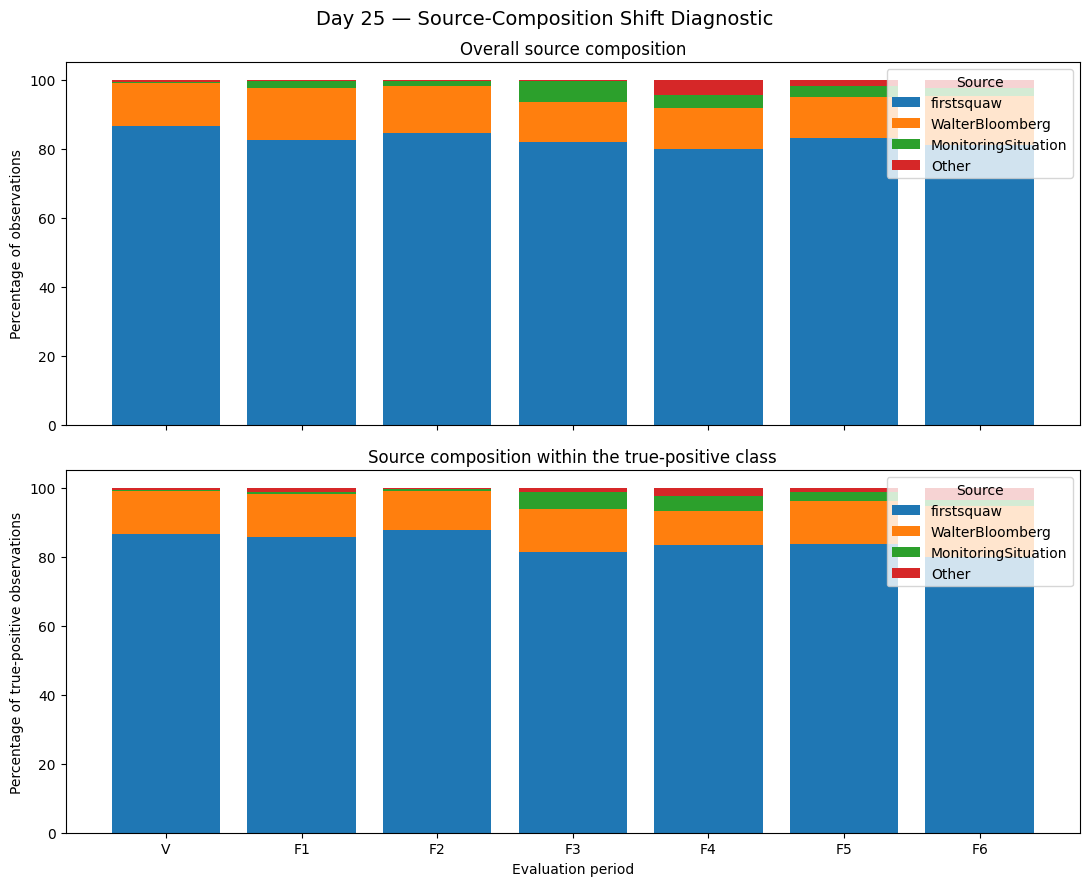

DAY 25 — STAGE 2 SOURCE-COMPOSITION FIGURE SAVE
Saved figure : /content/drive/MyDrive/FinGPT_Project/results/day25/source_composition_shift.png
Size         : 155,672 bytes
------------------------------------------------------------------------------------------------------------------------
PASS   — figure_exists
PASS   — figure_nonempty
------------------------------------------------------------------------------------------------------------------------
STATUS: PASS — Stage 2 source-composition diagnostic figure saved.


In [17]:
# ============================================================
# DAY 25 — CELL 13
# STAGE 2 SOURCE-COMPOSITION SHIFT FIGURE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Select major sources for interpretable visualization
# ------------------------------------------------------------

major_sources = [
    "firstsquaw",
    "WalterBloomberg",
    "MonitoringSituation",
]

def collapse_source_table(
    composition_df,
    major_sources,
):

    df = composition_df.copy()

    df["source_group"] = np.where(
        df["source"].isin(major_sources),
        df["source"],
        "Other",
    )

    collapsed = (
        df.groupby(
            [
                "period",
                "source_group",
            ],
            as_index=False,
        )[
            [
                "count",
                "proportion",
            ]
        ]
        .sum()
    )

    collapsed["percentage"] = (
        collapsed["proportion"]
        * 100
    )

    return collapsed


overall_collapsed = collapse_source_table(
    source_composition,
    major_sources,
)

positive_collapsed = collapse_source_table(
    positive_source_composition,
    major_sources,
)

source_group_order = [
    "firstsquaw",
    "WalterBloomberg",
    "MonitoringSituation",
    "Other",
]

# ------------------------------------------------------------
# Pivot for plotting
# ------------------------------------------------------------

overall_plot = (
    overall_collapsed
    .pivot(
        index="period",
        columns="source_group",
        values="percentage",
    )
    .reindex(
        index=period_order,
        columns=source_group_order,
        fill_value=0,
    )
)

positive_plot = (
    positive_collapsed
    .pivot(
        index="period",
        columns="source_group",
        values="percentage",
    )
    .reindex(
        index=period_order,
        columns=source_group_order,
        fill_value=0,
    )
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 9),
    sharex=True,
)

x = np.arange(
    len(period_order)
)

# Overall source composition
bottom = np.zeros(
    len(period_order)
)

for source_group in source_group_order:

    values = (
        overall_plot[
            source_group
        ].values
    )

    axes[0].bar(
        x,
        values,
        bottom=bottom,
        label=source_group,
    )

    bottom += values

axes[0].set_ylabel(
    "Percentage of observations"
)

axes[0].set_title(
    "Overall source composition"
)

axes[0].legend(
    title="Source",
    loc="upper right",
)

# Positive-only source composition
bottom = np.zeros(
    len(period_order)
)

for source_group in source_group_order:

    values = (
        positive_plot[
            source_group
        ].values
    )

    axes[1].bar(
        x,
        values,
        bottom=bottom,
        label=source_group,
    )

    bottom += values

axes[1].set_ylabel(
    "Percentage of true-positive observations"
)

axes[1].set_title(
    "Source composition within the true-positive class"
)

axes[1].legend(
    title="Source",
    loc="upper right",
)

axes[1].set_xticks(
    x
)

axes[1].set_xticklabels(
    period_order
)

axes[1].set_xlabel(
    "Evaluation period"
)

fig.suptitle(
    "Day 25 — Source-Composition Shift Diagnostic",
    fontsize=14,
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

SOURCE_COMPOSITION_FIGURE_PATH = (
    DAY25_RESULTS_ROOT
    / "source_composition_shift.png"
)

plt.savefig(
    SOURCE_COMPOSITION_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

figure_checks = {
    "figure_exists":
        SOURCE_COMPOSITION_FIGURE_PATH.exists(),

    "figure_nonempty":
        (
            SOURCE_COMPOSITION_FIGURE_PATH.exists()
            and
            SOURCE_COMPOSITION_FIGURE_PATH.stat().st_size > 0
        ),
}

print("=" * 120)
print("DAY 25 — STAGE 2 SOURCE-COMPOSITION FIGURE SAVE")
print("=" * 120)

print(
    f"Saved figure : "
    f"{SOURCE_COMPOSITION_FIGURE_PATH}"
)

if SOURCE_COMPOSITION_FIGURE_PATH.exists():

    print(
        f"Size         : "
        f"{SOURCE_COMPOSITION_FIGURE_PATH.stat().st_size:,} bytes"
    )

print("-" * 120)

for name, passed in figure_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    figure_checks.values()
):

    raise AssertionError(
        "Stage 2 source-composition figure save failed."
    )

print("-" * 120)

print(
    "STATUS: PASS — Stage 2 source-composition "
    "diagnostic figure saved."
)

print("=" * 120)

## Stage 3 — Source-Conditioned Performance Diagnosis

### Scientific Question

Is the F3 positive-recall failure concentrated in specific sources, or does it persist within the major sources that are shared across periods?

For each sufficiently represented source, this stage evaluates:

- total support;
- positive-class support;
- positive recall;
- negative recall;
- neutral recall;
- accuracy;
- Macro-F1;
- F3 positive → negative error counts;
- F3 positive → negative error rates.

Primary comparisons focus on V, F2, F3, and F4.

A source-mediated mechanism is supported if the residual F3 positive failure is concentrated in sources whose composition increased in F3. A broad decline within major common sources would weaken a pure source-composition explanation.

Small source cells will be flagged and excluded from stable interpretation.

In [18]:
# ============================================================
# DAY 25 — CELL 14
# SOURCE-CONDITIONED PERFORMANCE DIAGNOSIS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
)

# ------------------------------------------------------------
# Analysis population
# ------------------------------------------------------------

source_metric_population = pd.concat(
    [
        day25_validation[
            [
                "observation_id",
                "period",
                "source",
                "true_label",
                "predicted_label",
            ]
        ],
        day25_future[
            [
                "observation_id",
                "period",
                "source",
                "true_label",
                "predicted_label",
            ]
        ],
    ],
    ignore_index=True,
)

analysis_periods = [
    "V",
    "F2",
    "F3",
    "F4",
]

labels = [
    "negative",
    "neutral",
    "positive",
]

# ------------------------------------------------------------
# Minimum-support rule
# ------------------------------------------------------------

MIN_TOTAL_SUPPORT = 50
MIN_CLASS_SUPPORT = 20

# ------------------------------------------------------------
# Compute source-conditioned metrics
# ------------------------------------------------------------

metric_rows = []

for period in analysis_periods:

    df_period = source_metric_population[
        source_metric_population["period"]
        == period
    ]

    for source in sorted(
        df_period["source"].unique()
    ):

        df_source = df_period[
            df_period["source"]
            == source
        ]

        n = len(df_source)

        true_counts = (
            df_source["true_label"]
            .value_counts()
        )

        neg_support = int(
            true_counts.get(
                "negative",
                0,
            )
        )

        neu_support = int(
            true_counts.get(
                "neutral",
                0,
            )
        )

        pos_support = int(
            true_counts.get(
                "positive",
                0,
            )
        )

        accuracy = accuracy_score(
            df_source["true_label"],
            df_source["predicted_label"],
        )

        macro_f1 = f1_score(
            df_source["true_label"],
            df_source["predicted_label"],
            labels=labels,
            average="macro",
            zero_division=0,
        )

        # ----------------------------------------------------
        # Per-class recall
        # ----------------------------------------------------

        class_recalls = recall_score(
            df_source["true_label"],
            df_source["predicted_label"],
            labels=labels,
            average=None,
            zero_division=0,
        )

        recall_map = dict(
            zip(
                labels,
                class_recalls,
            )
        )

        # ----------------------------------------------------
        # Positive error decomposition
        # ----------------------------------------------------

        positive_df = df_source[
            df_source["true_label"]
            == "positive"
        ]

        pos_to_neg = int(
            (
                positive_df[
                    "predicted_label"
                ]
                == "negative"
            ).sum()
        )

        pos_to_neu = int(
            (
                positive_df[
                    "predicted_label"
                ]
                == "neutral"
            ).sum()
        )

        pos_to_pos = int(
            (
                positive_df[
                    "predicted_label"
                ]
                == "positive"
            ).sum()
        )

        pos_to_neg_rate = (
            pos_to_neg / pos_support
            if pos_support > 0
            else np.nan
        )

        stable_total = (
            n >= MIN_TOTAL_SUPPORT
        )

        stable_positive = (
            pos_support
            >= MIN_CLASS_SUPPORT
        )

        metric_rows.append(
            {
                "period": period,
                "source": source,

                "n": int(n),

                "negative_support":
                    neg_support,

                "neutral_support":
                    neu_support,

                "positive_support":
                    pos_support,

                "accuracy":
                    float(accuracy),

                "macro_f1":
                    float(macro_f1),

                "negative_recall":
                    float(
                        recall_map[
                            "negative"
                        ]
                    ),

                "neutral_recall":
                    float(
                        recall_map[
                            "neutral"
                        ]
                    ),

                "positive_recall":
                    float(
                        recall_map[
                            "positive"
                        ]
                    ),

                "positive_to_negative":
                    pos_to_neg,

                "positive_to_neutral":
                    pos_to_neu,

                "positive_to_positive":
                    pos_to_pos,

                "positive_to_negative_rate":
                    float(
                        pos_to_neg_rate
                    )
                    if not np.isnan(
                        pos_to_neg_rate
                    )
                    else np.nan,

                "stable_total_support":
                    bool(
                        stable_total
                    ),

                "stable_positive_support":
                    bool(
                        stable_positive
                    ),
            }
        )

source_conditioned_metrics = pd.DataFrame(
    metric_rows
)

# ------------------------------------------------------------
# Save canonical artifact
# ------------------------------------------------------------

SOURCE_CONDITIONED_METRICS_PATH = (
    DAY25_RESULTS_ROOT
    / "source_conditioned_metrics.csv"
)

source_conditioned_metrics.to_csv(
    SOURCE_CONDITIONED_METRICS_PATH,
    index=False,
)

# ------------------------------------------------------------
# Stable-source display
# ------------------------------------------------------------

stable_display = (
    source_conditioned_metrics[
        source_conditioned_metrics[
            "stable_positive_support"
        ]
    ]
    .copy()
    .sort_values(
        [
            "source",
            "period",
        ]
    )
)

# ------------------------------------------------------------
# F3 positive-error ranking
# ------------------------------------------------------------

f3_error_ranking = (
    source_conditioned_metrics[
        source_conditioned_metrics[
            "period"
        ] == "F3"
    ]
    .copy()
    .sort_values(
        [
            "positive_to_negative",
            "positive_to_negative_rate",
        ],
        ascending=[
            False,
            False,
        ],
    )
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

f3_positive_total = int(
    f3_error_ranking[
        "positive_support"
    ].sum()
)

f3_pos_to_neg_total = int(
    f3_error_ranking[
        "positive_to_negative"
    ].sum()
)

f3_pos_to_neu_total = int(
    f3_error_ranking[
        "positive_to_neutral"
    ].sum()
)

f3_pos_to_pos_total = int(
    f3_error_ranking[
        "positive_to_positive"
    ].sum()
)

checks = {
    "f3_positive_support_544":
        f3_positive_total == 544,

    "f3_positive_to_negative_104":
        f3_pos_to_neg_total == 104,

    "f3_positive_to_neutral_94":
        f3_pos_to_neu_total == 94,

    "f3_positive_to_positive_346":
        f3_pos_to_pos_total == 346,
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — SOURCE-CONDITIONED PERFORMANCE DIAGNOSIS")
print("=" * 120)

print(
    f"Minimum total support : {MIN_TOTAL_SUPPORT}"
)

print(
    f"Minimum class support : {MIN_CLASS_SUPPORT}"
)

print("-" * 120)
print("STABLE SOURCE-CONDITIONED METRICS")
print("-" * 120)

display_cols = [
    "period",
    "source",
    "n",
    "positive_support",
    "accuracy",
    "macro_f1",
    "negative_recall",
    "neutral_recall",
    "positive_recall",
    "positive_to_negative",
    "positive_to_negative_rate",
]

print(
    stable_display[
        display_cols
    ]
    .round(
        {
            "accuracy": 4,
            "macro_f1": 4,
            "negative_recall": 4,
            "neutral_recall": 4,
            "positive_recall": 4,
            "positive_to_negative_rate": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("F3 POSITIVE-ERROR CONCENTRATION BY SOURCE")
print("-" * 120)

print(
    f3_error_ranking[
        [
            "source",
            "n",
            "positive_support",
            "positive_recall",
            "positive_to_negative",
            "positive_to_negative_rate",
            "stable_positive_support",
        ]
    ]
    .round(
        {
            "positive_recall": 4,
            "positive_to_negative_rate": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("F3 ERROR-DECOMPOSITION CHECKS")
print("-" * 120)

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    checks.values()
):

    failed = [
        name
        for name, passed
        in checks.items()
        if not passed
    ]

    raise AssertionError(
        "Stage 3 F3 error decomposition failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: {SOURCE_CONDITIONED_METRICS_PATH}"
)

print(
    "STATUS: PASS — source-conditioned performance "
    "and F3 positive-error concentration quantified."
)

print("=" * 120)

DAY 25 — SOURCE-CONDITIONED PERFORMANCE DIAGNOSIS
Minimum total support : 50
Minimum class support : 20
------------------------------------------------------------------------------------------------------------------------
STABLE SOURCE-CONDITIONED METRICS
------------------------------------------------------------------------------------------------------------------------
period              source    n  positive_support  accuracy  macro_f1  negative_recall  neutral_recall  positive_recall  positive_to_negative  positive_to_negative_rate
    F3 MonitoringSituation  291                27    0.7216    0.6241           0.7361          0.8000           0.2963                    16                     0.5926
    F4 MonitoringSituation  153                27    0.8235    0.8116           0.7800          0.8947           0.7037                     4                     0.1481
    F2     WalterBloomberg  478                69    0.8452    0.8233           0.7951          0.8641           

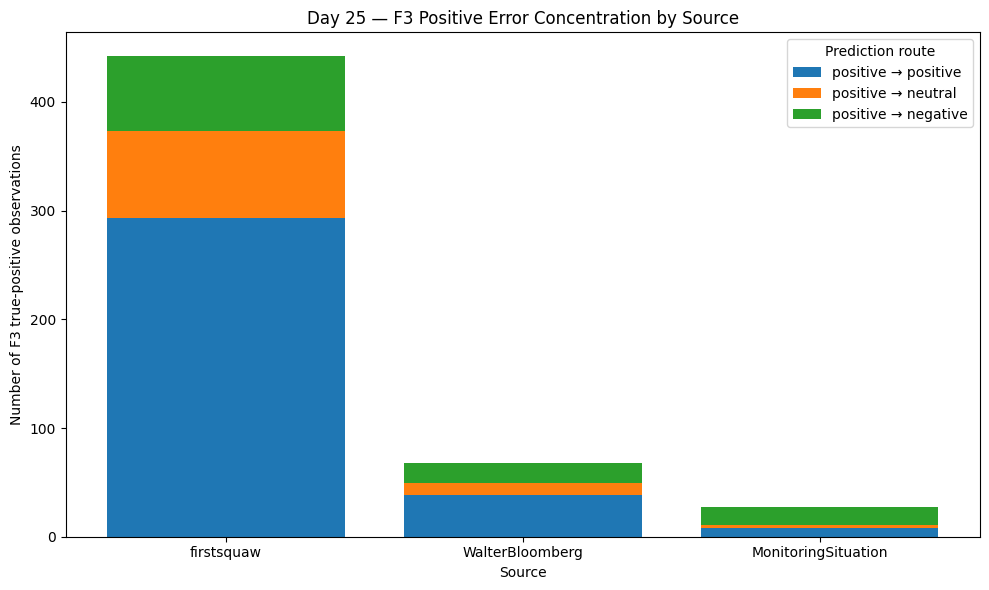

DAY 25 — F3 POSITIVE ERROR CONCENTRATION FIGURE
             source  positive_support  positive_to_positive  positive_to_neutral  positive_to_negative  positive_recall  positive_to_negative_rate
         firstsquaw               442                   293                   80                    69           0.6629                     0.1561
    WalterBloomberg                68                    38                   11                    19           0.5588                     0.2794
MonitoringSituation                27                     8                    3                    16           0.2963                     0.5926
------------------------------------------------------------------------------------------------------------------------
Saved figure : /content/drive/MyDrive/FinGPT_Project/results/day25/f3_positive_error_concentration_by_source.png
Saved table  : /content/drive/MyDrive/FinGPT_Project/results/day25/f3_positive_error_concentration_by_source.csv
-----------------

In [19]:
# ============================================================
# DAY 25 — CELL 15
# F3 POSITIVE ERROR CONCENTRATION FIGURE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Restrict to stable F3 sources
# ------------------------------------------------------------

f3_stable_sources = (
    source_conditioned_metrics[
        (source_conditioned_metrics["period"] == "F3")
        &
        (
            source_conditioned_metrics[
                "stable_positive_support"
            ]
        )
    ]
    .copy()
)

# Order by positive support
f3_stable_sources = (
    f3_stable_sources
    .sort_values(
        "positive_support",
        ascending=False,
    )
)

# ------------------------------------------------------------
# Prepare stacked counts
# ------------------------------------------------------------

sources = (
    f3_stable_sources["source"]
    .tolist()
)

correct_counts = (
    f3_stable_sources[
        "positive_to_positive"
    ]
    .to_numpy()
)

neutral_error_counts = (
    f3_stable_sources[
        "positive_to_neutral"
    ]
    .to_numpy()
)

negative_error_counts = (
    f3_stable_sources[
        "positive_to_negative"
    ]
    .to_numpy()
)

x = np.arange(
    len(sources)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    x,
    correct_counts,
    label="positive → positive",
)

ax.bar(
    x,
    neutral_error_counts,
    bottom=correct_counts,
    label="positive → neutral",
)

ax.bar(
    x,
    negative_error_counts,
    bottom=(
        correct_counts
        + neutral_error_counts
    ),
    label="positive → negative",
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    sources
)

ax.set_ylabel(
    "Number of F3 true-positive observations"
)

ax.set_xlabel(
    "Source"
)

ax.set_title(
    "Day 25 — F3 Positive Error Concentration by Source"
)

ax.legend(
    title="Prediction route"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

F3_SOURCE_ERROR_FIGURE_PATH = (
    DAY25_RESULTS_ROOT
    / "f3_positive_error_concentration_by_source.png"
)

plt.savefig(
    F3_SOURCE_ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Save supporting table
# ------------------------------------------------------------

F3_SOURCE_ERROR_TABLE_PATH = (
    DAY25_RESULTS_ROOT
    / "f3_positive_error_concentration_by_source.csv"
)

f3_source_error_table = (
    f3_stable_sources[
        [
            "source",
            "positive_support",
            "positive_to_positive",
            "positive_to_neutral",
            "positive_to_negative",
            "positive_recall",
            "positive_to_negative_rate",
        ]
    ]
    .copy()
)

f3_source_error_table.to_csv(
    F3_SOURCE_ERROR_TABLE_PATH,
    index=False,
)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

checks = {
    "figure_exists":
        F3_SOURCE_ERROR_FIGURE_PATH.exists(),

    "figure_nonempty":
        (
            F3_SOURCE_ERROR_FIGURE_PATH.exists()
            and
            F3_SOURCE_ERROR_FIGURE_PATH.stat().st_size > 0
        ),

    "table_exists":
        F3_SOURCE_ERROR_TABLE_PATH.exists(),

    "table_nonempty":
        (
            F3_SOURCE_ERROR_TABLE_PATH.exists()
            and
            F3_SOURCE_ERROR_TABLE_PATH.stat().st_size > 0
        ),

    "stable_sources_three":
        len(
            f3_source_error_table
        ) == 3,

    "positive_support_537":
        int(
            f3_source_error_table[
                "positive_support"
            ].sum()
        ) == 537,

    "positive_to_negative_104":
        int(
            f3_source_error_table[
                "positive_to_negative"
            ].sum()
        ) == 104,
}

print("=" * 120)
print("DAY 25 — F3 POSITIVE ERROR CONCENTRATION FIGURE")
print("=" * 120)

print(
    f3_source_error_table
    .round(
        {
            "positive_recall": 4,
            "positive_to_negative_rate": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)

print(
    f"Saved figure : "
    f"{F3_SOURCE_ERROR_FIGURE_PATH}"
)

print(
    f"Saved table  : "
    f"{F3_SOURCE_ERROR_TABLE_PATH}"
)

print("-" * 120)

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(checks.values()):

    failed = [
        name
        for name, passed
        in checks.items()
        if not passed
    ]

    raise AssertionError(
        "F3 source-error concentration "
        "figure/table verification failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    "STATUS: PASS — F3 positive-error concentration "
    "across stable sources visualized and saved."
)

print("=" * 120)

In [20]:
# ============================================================
# DAY 25 — CELL 16
# SOURCE-CONDITIONED POSITIVE-RECALL BOOTSTRAP
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Frozen bootstrap protocol
# ------------------------------------------------------------

N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

# ------------------------------------------------------------
# Pre-specified contrasts only
# ------------------------------------------------------------

bootstrap_contrasts = [
    ("firstsquaw", "V"),
    ("firstsquaw", "F2"),
    ("firstsquaw", "F4"),

    ("WalterBloomberg", "V"),
    ("WalterBloomberg", "F2"),
    ("WalterBloomberg", "F4"),

    ("MonitoringSituation", "F4"),
]

# ------------------------------------------------------------
# Helper: positive-class correctness vector
# ------------------------------------------------------------

def positive_correctness_vector(
    df,
    source,
    period,
):
    subset = df[
        (df["source"] == source)
        &
        (df["period"] == period)
        &
        (df["true_label"] == "positive")
    ].copy()

    correctness = (
        subset["predicted_label"]
        .eq("positive")
        .astype(int)
        .to_numpy()
    )

    return correctness


# ------------------------------------------------------------
# Bootstrap each contrast
# ------------------------------------------------------------

bootstrap_rows = []

for source, reference_period in bootstrap_contrasts:

    f3_vec = positive_correctness_vector(
        source_metric_population,
        source,
        "F3",
    )

    ref_vec = positive_correctness_vector(
        source_metric_population,
        source,
        reference_period,
    )

    n_f3 = len(f3_vec)
    n_ref = len(ref_vec)

    if n_f3 < MIN_CLASS_SUPPORT:
        raise ValueError(
            f"F3 positive support too small for {source}: "
            f"{n_f3}"
        )

    if n_ref < MIN_CLASS_SUPPORT:
        raise ValueError(
            f"{reference_period} positive support too small "
            f"for {source}: {n_ref}"
        )

    f3_recall = float(
        f3_vec.mean()
    )

    ref_recall = float(
        ref_vec.mean()
    )

    observed_delta = (
        f3_recall
        - ref_recall
    )

    bootstrap_deltas = np.empty(
        N_BOOTSTRAP,
        dtype=float,
    )

    for b in range(
        N_BOOTSTRAP
    ):

        f3_sample = rng.choice(
            f3_vec,
            size=n_f3,
            replace=True,
        )

        ref_sample = rng.choice(
            ref_vec,
            size=n_ref,
            replace=True,
        )

        bootstrap_deltas[b] = (
            f3_sample.mean()
            - ref_sample.mean()
        )

    ci_low = float(
        np.percentile(
            bootstrap_deltas,
            2.5,
        )
    )

    ci_high = float(
        np.percentile(
            bootstrap_deltas,
            97.5,
        )
    )

    bootstrap_rows.append(
        {
            "source": source,
            "metric": "positive_recall",
            "target_period": "F3",
            "reference_period":
                reference_period,

            "f3_positive_support":
                int(n_f3),

            "reference_positive_support":
                int(n_ref),

            "f3_positive_recall":
                f3_recall,

            "reference_positive_recall":
                ref_recall,

            "delta_f3_minus_reference":
                observed_delta,

            "ci_low_95":
                ci_low,

            "ci_high_95":
                ci_high,

            "ci_excludes_zero":
                bool(
                    (ci_low > 0)
                    or
                    (ci_high < 0)
                ),

            "n_bootstrap":
                N_BOOTSTRAP,

            "seed":
                BOOTSTRAP_SEED,
        }
    )

source_recall_bootstrap = pd.DataFrame(
    bootstrap_rows
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

SOURCE_RECALL_BOOTSTRAP_PATH = (
    DAY25_RESULTS_ROOT
    / "source_conditioned_positive_recall_bootstrap.csv"
)

source_recall_bootstrap.to_csv(
    SOURCE_RECALL_BOOTSTRAP_PATH,
    index=False,
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

bootstrap_checks = {
    "seven_prespecified_contrasts":
        len(source_recall_bootstrap) == 7,

    "all_f3_support_stable":
        (
            source_recall_bootstrap[
                "f3_positive_support"
            ]
            >= MIN_CLASS_SUPPORT
        ).all(),

    "all_reference_support_stable":
        (
            source_recall_bootstrap[
                "reference_positive_support"
            ]
            >= MIN_CLASS_SUPPORT
        ).all(),

    "all_ci_order_valid":
        (
            source_recall_bootstrap[
                "ci_low_95"
            ]
            <=
            source_recall_bootstrap[
                "ci_high_95"
            ]
        ).all(),

    "bootstrap_replicates_1000":
        (
            source_recall_bootstrap[
                "n_bootstrap"
            ]
            == 1000
        ).all(),
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — SOURCE-CONDITIONED POSITIVE-RECALL BOOTSTRAP")
print("=" * 120)

print(
    source_recall_bootstrap[
        [
            "source",
            "reference_period",
            "f3_positive_support",
            "reference_positive_support",
            "f3_positive_recall",
            "reference_positive_recall",
            "delta_f3_minus_reference",
            "ci_low_95",
            "ci_high_95",
            "ci_excludes_zero",
        ]
    ]
    .round(
        {
            "f3_positive_recall": 4,
            "reference_positive_recall": 4,
            "delta_f3_minus_reference": 4,
            "ci_low_95": 4,
            "ci_high_95": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("BOOTSTRAP INTEGRITY CHECKS")
print("-" * 120)

for name, passed in bootstrap_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    bootstrap_checks.values()
):

    failed = [
        name
        for name, passed
        in bootstrap_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Source-conditioned bootstrap integrity failure: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: {SOURCE_RECALL_BOOTSTRAP_PATH}"
)

print(
    "STATUS: PASS — pre-specified major-source "
    "positive-recall contrasts bootstrapped."
)

print("=" * 120)

DAY 25 — SOURCE-CONDITIONED POSITIVE-RECALL BOOTSTRAP
             source reference_period  f3_positive_support  reference_positive_support  f3_positive_recall  reference_positive_recall  delta_f3_minus_reference  ci_low_95  ci_high_95  ci_excludes_zero
         firstsquaw                V                  442                         900              0.6629                     0.8100                   -0.1471    -0.1944     -0.0966              True
         firstsquaw               F2                  442                         531              0.6629                     0.8192                   -0.1563    -0.2095     -0.0982              True
         firstsquaw               F4                  442                         514              0.6629                     0.7665                   -0.1036    -0.1597     -0.0464              True
    WalterBloomberg                V                   68                         131              0.5588                     0.8321              

## Stage 4 — F3 Positive Error-Cohort Construction

### Scientific Question

What distinguishes the F3 positive → negative errors from correctly classified F3 positives?

The F3 true-positive population will be frozen into three immutable cohorts:

- **positive → positive**: correctly classified positives;
- **positive → negative**: directional failure cohort;
- **positive → neutral**: secondary error cohort.

The expected counts are:

\[
346,\qquad 104,\qquad 94,
\]

respectively.

No observations will be manually removed after inspecting their text. Each cohort will retain stable observation identity, source, timestamp, text, true label, and predicted label, and will be frozen with ordered observation-ID hashes before any lexical analysis.

In [21]:
# ============================================================
# DAY 25 — CELL 17
# F3 POSITIVE ERROR-COHORT FREEZE
# ============================================================

import json
import hashlib
from datetime import datetime, timezone

# ------------------------------------------------------------
# Construct immutable F3 true-positive population
# ------------------------------------------------------------

f3_positive = (
    day25_future[
        (day25_future["period"] == "F3")
        &
        (day25_future["true_label"] == "positive")
    ]
    .copy()
)

# ------------------------------------------------------------
# Assign prediction-route cohort
# ------------------------------------------------------------

def assign_positive_route(predicted_label):

    if predicted_label == "positive":
        return "positive_to_positive"

    elif predicted_label == "negative":
        return "positive_to_negative"

    elif predicted_label == "neutral":
        return "positive_to_neutral"

    else:
        raise ValueError(
            f"Unexpected predicted label: {predicted_label}"
        )


f3_positive["cohort"] = (
    f3_positive["predicted_label"]
    .apply(assign_positive_route)
)

# ------------------------------------------------------------
# Canonical cohort columns
# ------------------------------------------------------------

cohort_columns = [
    "observation_id",
    "timestamp",
    "period",
    "source",
    "message_id",
    "text",
    "true_label",
    "predicted_label",
    "cohort",
]

f3_positive_cohorts = (
    f3_positive[
        cohort_columns
    ]
    .copy()
)

# ------------------------------------------------------------
# Expected cohort counts
# ------------------------------------------------------------

expected_cohort_counts = {
    "positive_to_positive": 346,
    "positive_to_negative": 104,
    "positive_to_neutral": 94,
}

observed_cohort_counts = (
    f3_positive_cohorts[
        "cohort"
    ]
    .value_counts()
    .to_dict()
)

# ------------------------------------------------------------
# Ordered-ID hashes by cohort
# ------------------------------------------------------------

def ordered_id_hash(df):

    ordered_ids = (
        df["observation_id"]
        .astype(str)
        .tolist()
    )

    return hashlib.sha256(
        "\n".join(
            ordered_ids
        ).encode("utf-8")
    ).hexdigest()


cohort_hashes = {}

for cohort_name in expected_cohort_counts:

    cohort_df = (
        f3_positive_cohorts[
            f3_positive_cohorts["cohort"]
            == cohort_name
        ]
    )

    cohort_hashes[
        cohort_name
    ] = {
        "n": int(
            len(cohort_df)
        ),
        "ordered_observation_id_sha256":
            ordered_id_hash(
                cohort_df
            ),
    }

# ------------------------------------------------------------
# Overall F3 positive ordered-ID hash
# ------------------------------------------------------------

overall_f3_positive_hash = (
    ordered_id_hash(
        f3_positive_cohorts
    )
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

cohort_checks = {
    "f3_positive_total_544":
        len(
            f3_positive_cohorts
        ) == 544,

    "positive_to_positive_346":
        observed_cohort_counts.get(
            "positive_to_positive",
            0,
        ) == 346,

    "positive_to_negative_104":
        observed_cohort_counts.get(
            "positive_to_negative",
            0,
        ) == 104,

    "positive_to_neutral_94":
        observed_cohort_counts.get(
            "positive_to_neutral",
            0,
        ) == 94,

    "observation_ids_unique":
        f3_positive_cohorts[
            "observation_id"
        ].is_unique,

    "observation_ids_nonmissing":
        f3_positive_cohorts[
            "observation_id"
        ].notna().all(),

    "source_nonmissing":
        f3_positive_cohorts[
            "source"
        ].notna().all(),

    "timestamp_nonmissing":
        f3_positive_cohorts[
            "timestamp"
        ].notna().all(),

    "text_nonmissing":
        f3_positive_cohorts[
            "text"
        ].notna().all(),

    "all_true_labels_positive":
        (
            f3_positive_cohorts[
                "true_label"
            ]
            == "positive"
        ).all(),

    "all_period_f3":
        (
            f3_positive_cohorts[
                "period"
            ]
            == "F3"
        ).all(),
}

# ------------------------------------------------------------
# Save cohort artifact
# ------------------------------------------------------------

F3_COHORT_PATH = (
    DAY25_RESULTS_ROOT
    / "f3_positive_error_cohorts.csv"
)

f3_positive_cohorts.to_csv(
    F3_COHORT_PATH,
    index=False,
)

# ------------------------------------------------------------
# Build cohort manifest
# ------------------------------------------------------------

f3_cohort_manifest = {
    "day": 25,

    "artifact":
        "f3_positive_error_cohort_manifest",

    "status":
        "FROZEN",

    "scientific_role":
        (
            "immutable F3 true-positive prediction-route cohorts "
            "for downstream lexical and joint source analyses"
        ),

    "population": {
        "period": "F3",
        "true_label": "positive",
        "n": 544,
        "ordered_observation_id_sha256":
            overall_f3_positive_hash,
    },

    "cohorts":
        cohort_hashes,

    "expected_counts":
        expected_cohort_counts,

    "manual_exclusion_allowed":
        False,

    "source_artifact": {
        "path":
            str(
                DAY24_OPTIMIZED_FUTURE_PREDICTIONS
            ),
        "sha256":
            current_prediction_sha256,
    },

    "cohort_artifact": {
        "path":
            str(
                F3_COHORT_PATH
            ),
    },

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

F3_COHORT_MANIFEST_PATH = (
    DAY25_RESULTS_ROOT
    / "f3_positive_error_cohort_manifest.json"
)

with open(
    F3_COHORT_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        f3_cohort_manifest,
        f,
        indent=2,
        ensure_ascii=False,
    )

# ------------------------------------------------------------
# Verify saved artifacts
# ------------------------------------------------------------

save_checks = {
    "cohort_csv_exists":
        F3_COHORT_PATH.exists(),

    "cohort_csv_nonempty":
        (
            F3_COHORT_PATH.exists()
            and
            F3_COHORT_PATH.stat().st_size > 0
        ),

    "manifest_exists":
        F3_COHORT_MANIFEST_PATH.exists(),

    "manifest_nonempty":
        (
            F3_COHORT_MANIFEST_PATH.exists()
            and
            F3_COHORT_MANIFEST_PATH.stat().st_size > 0
        ),
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — F3 POSITIVE ERROR-COHORT FREEZE")
print("=" * 120)

print(
    f"F3 true-positive population : "
    f"{len(f3_positive_cohorts)}"
)

print(
    f"Ordered ID SHA256           : "
    f"{overall_f3_positive_hash}"
)

print("-" * 120)
print("COHORT COUNTS AND HASHES")
print("-" * 120)

for cohort_name in [
    "positive_to_positive",
    "positive_to_negative",
    "positive_to_neutral",
]:

    info = (
        cohort_hashes[
            cohort_name
        ]
    )

    print(
        f"{cohort_name:<24} "
        f"n={info['n']:<4} "
        f"sha256={info['ordered_observation_id_sha256']}"
    )

print("-" * 120)
print("COHORT INTEGRITY CHECKS")
print("-" * 120)

for name, passed in cohort_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

print("-" * 120)
print("SAVE CHECKS")
print("-" * 120)

for name, passed in save_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

all_checks = {
    **cohort_checks,
    **save_checks,
}

if not all(
    all_checks.values()
):

    failed = [
        name
        for name, passed
        in all_checks.items()
        if not passed
    ]

    raise AssertionError(
        "F3 positive cohort freeze failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved cohort artifact : "
    f"{F3_COHORT_PATH}"
)

print(
    f"Saved cohort manifest : "
    f"{F3_COHORT_MANIFEST_PATH}"
)

print(
    "STATUS: PASS — F3 positive error cohorts "
    "frozen and ready for lexical diagnosis."
)

print("=" * 120)

DAY 25 — F3 POSITIVE ERROR-COHORT FREEZE
F3 true-positive population : 544
Ordered ID SHA256           : ef3229c853b722a3b988cb7b699eb7c76f2c840e9cb93a48b6f4c8ed54c2c074
------------------------------------------------------------------------------------------------------------------------
COHORT COUNTS AND HASHES
------------------------------------------------------------------------------------------------------------------------
positive_to_positive     n=346  sha256=a63417ba4fb803b0e218ffc2c93fa1c32eb0e97ec1eb3c2b45ee15054a8a6131
positive_to_negative     n=104  sha256=080e886fc08d4b1cb8573206b6b6f2445434a698d305c0b203907673037325af
positive_to_neutral      n=94   sha256=c5c04d5cc716c161655c7970000a15b0a0c2e1067a9268b0e62aab4d7230c460
------------------------------------------------------------------------------------------------------------------------
COHORT INTEGRITY CHECKS
----------------------------------------------------------------------------------------------------------

## Stage 5 — Lexical Shift Analysis

### Primary Lightweight Mechanism Test

The first lexical comparison focuses on the most direct residual-failure contrast:

\[
\text{F3 positive → negative}
\quad \text{vs} \quad
\text{F3 positive → positive}.
\]

This analysis asks whether the 104 directional positive → negative failures exhibit systematic lexical structure that differs from the 346 correctly classified F3 positives.

### Frozen Lexical Protocol

- Original text is preserved unchanged.
- Lowercasing is used only inside TF-IDF vectorization.
- Unigrams and bigrams are included.
- No manually selected sentiment terms are removed.
- No examples are excluded after text inspection.
- Rare one-off terms are filtered using a documented minimum document-frequency rule.
- Lexical differences are interpreted as associations, not causal mechanisms.

The primary statistic is the difference in mean TF-IDF weight between the two frozen cohorts, accompanied by document-frequency support.

In [22]:
# ============================================================
# DAY 25 — CELL 18
# F3 POSITIVE→NEGATIVE VS POSITIVE→POSITIVE
# TF-IDF LEXICAL CONTRAST
# ============================================================

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------------------
# Frozen comparison cohorts
# ------------------------------------------------------------

lexical_cohorts = (
    f3_positive_cohorts[
        f3_positive_cohorts["cohort"].isin(
            [
                "positive_to_negative",
                "positive_to_positive",
            ]
        )
    ]
    .copy()
)

posneg = (
    lexical_cohorts[
        lexical_cohorts["cohort"]
        == "positive_to_negative"
    ]
    .copy()
)

pospos = (
    lexical_cohorts[
        lexical_cohorts["cohort"]
        == "positive_to_positive"
    ]
    .copy()
)

# ------------------------------------------------------------
# Frozen TF-IDF protocol
# ------------------------------------------------------------

TFIDF_NGRAM_RANGE = (1, 2)
TFIDF_MIN_DF = 5
TFIDF_MAX_DF = 0.95
TFIDF_SUBLINEAR_TF = True

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=TFIDF_NGRAM_RANGE,
    min_df=TFIDF_MIN_DF,
    max_df=TFIDF_MAX_DF,
    sublinear_tf=TFIDF_SUBLINEAR_TF,
    norm="l2",
)

# ------------------------------------------------------------
# Fit vocabulary on the frozen two-cohort comparison only
# ------------------------------------------------------------

X = vectorizer.fit_transform(
    lexical_cohorts["text"]
    .astype(str)
    .tolist()
)

feature_names = np.array(
    vectorizer.get_feature_names_out()
)

cohort_labels = (
    lexical_cohorts["cohort"]
    .to_numpy()
)

mask_posneg = (
    cohort_labels
    == "positive_to_negative"
)

mask_pospos = (
    cohort_labels
    == "positive_to_positive"
)

X_posneg = X[
    mask_posneg
]

X_pospos = X[
    mask_pospos
]

# ------------------------------------------------------------
# Mean TF-IDF by cohort
# ------------------------------------------------------------

mean_posneg = np.asarray(
    X_posneg.mean(axis=0)
).ravel()

mean_pospos = np.asarray(
    X_pospos.mean(axis=0)
).ravel()

mean_difference = (
    mean_posneg
    - mean_pospos
)

# ------------------------------------------------------------
# Document-frequency support
# ------------------------------------------------------------

df_posneg = np.asarray(
    (X_posneg > 0)
    .sum(axis=0)
).ravel()

df_pospos = np.asarray(
    (X_pospos > 0)
    .sum(axis=0)
).ravel()

df_total = (
    df_posneg
    + df_pospos
)

df_rate_posneg = (
    df_posneg
    / len(posneg)
)

df_rate_pospos = (
    df_pospos
    / len(pospos)
)

df_rate_difference = (
    df_rate_posneg
    - df_rate_pospos
)

# ------------------------------------------------------------
# Assemble lexical evidence table
# ------------------------------------------------------------

lexical_contrast = pd.DataFrame(
    {
        "term": feature_names,

        "mean_tfidf_posneg":
            mean_posneg,

        "mean_tfidf_pospos":
            mean_pospos,

        "mean_tfidf_difference":
            mean_difference,

        "abs_mean_tfidf_difference":
            np.abs(
                mean_difference
            ),

        "df_posneg":
            df_posneg.astype(int),

        "df_pospos":
            df_pospos.astype(int),

        "df_total":
            df_total.astype(int),

        "df_rate_posneg":
            df_rate_posneg,

        "df_rate_pospos":
            df_rate_pospos,

        "df_rate_difference":
            df_rate_difference,
    }
)

lexical_contrast["direction"] = np.where(
    lexical_contrast[
        "mean_tfidf_difference"
    ] > 0,
    "enriched_in_positive_to_negative",
    "enriched_in_positive_to_positive",
)

# Rank primarily by absolute mean TF-IDF difference.
lexical_contrast = (
    lexical_contrast
    .sort_values(
        "abs_mean_tfidf_difference",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

lexical_checks = {
    "positive_to_negative_n_104":
        len(posneg) == 104,

    "positive_to_positive_n_346":
        len(pospos) == 346,

    "combined_n_450":
        len(lexical_cohorts) == 450,

    "vocabulary_nonempty":
        len(feature_names) > 0,

    "all_terms_meet_min_df":
        (
            lexical_contrast[
                "df_total"
            ]
            >= TFIDF_MIN_DF
        ).all(),

    "no_missing_terms":
        lexical_contrast[
            "term"
        ].notna().all(),

    "no_missing_statistics":
        lexical_contrast[
            [
                "mean_tfidf_posneg",
                "mean_tfidf_pospos",
                "mean_tfidf_difference",
                "df_posneg",
                "df_pospos",
            ]
        ]
        .notna()
        .all()
        .all(),
}

# ------------------------------------------------------------
# Save canonical lexical artifact
# ------------------------------------------------------------

LEXICAL_CONTRAST_PATH = (
    DAY25_RESULTS_ROOT
    / "lexical_contrast_f3_posneg_vs_pospos.csv"
)

lexical_contrast.to_csv(
    LEXICAL_CONTRAST_PATH,
    index=False,
)

# ------------------------------------------------------------
# Compact top-term displays
# ------------------------------------------------------------

TOP_N = 20

top_posneg = (
    lexical_contrast[
        lexical_contrast["mean_tfidf_difference"]
        > 0
    ]
    .nlargest(
        TOP_N,
        "mean_tfidf_difference",
    )
)

top_pospos = (
    lexical_contrast[
        lexical_contrast["mean_tfidf_difference"]
        < 0
    ]
    .nsmallest(
        TOP_N,
        "mean_tfidf_difference",
    )
)

display_columns = [
    "term",
    "mean_tfidf_posneg",
    "mean_tfidf_pospos",
    "mean_tfidf_difference",
    "df_posneg",
    "df_pospos",
    "df_rate_posneg",
    "df_rate_pospos",
]

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — F3 POSNEG VS POSPOS TF-IDF LEXICAL CONTRAST")
print("=" * 120)

print(
    f"Positive → negative cohort : "
    f"{len(posneg)}"
)

print(
    f"Positive → positive cohort : "
    f"{len(pospos)}"
)

print(
    f"TF-IDF vocabulary size     : "
    f"{len(feature_names):,}"
)

print(
    f"N-gram range               : "
    f"{TFIDF_NGRAM_RANGE}"
)

print(
    f"Minimum document frequency : "
    f"{TFIDF_MIN_DF}"
)

print(
    f"Maximum document frequency : "
    f"{TFIDF_MAX_DF}"
)

print("-" * 120)
print("TOP TERMS ENRICHED IN POSITIVE → NEGATIVE")
print("-" * 120)

print(
    top_posneg[
        display_columns
    ]
    .round(
        {
            "mean_tfidf_posneg": 5,
            "mean_tfidf_pospos": 5,
            "mean_tfidf_difference": 5,
            "df_rate_posneg": 4,
            "df_rate_pospos": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("TOP TERMS ENRICHED IN POSITIVE → POSITIVE")
print("-" * 120)

print(
    top_pospos[
        display_columns
    ]
    .round(
        {
            "mean_tfidf_posneg": 5,
            "mean_tfidf_pospos": 5,
            "mean_tfidf_difference": 5,
            "df_rate_posneg": 4,
            "df_rate_pospos": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("LEXICAL INTEGRITY CHECKS")
print("-" * 120)

for name, passed in lexical_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    lexical_checks.values()
):

    failed = [
        name
        for name, passed
        in lexical_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Stage 5 lexical contrast integrity failure: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: {LEXICAL_CONTRAST_PATH}"
)

print(
    "STATUS: PASS — frozen F3 positive→negative "
    "vs positive→positive lexical contrast completed."
)

print("=" * 120)

DAY 25 — F3 POSNEG VS POSPOS TF-IDF LEXICAL CONTRAST
Positive → negative cohort : 104
Positive → positive cohort : 346
TF-IDF vocabulary size     : 339
N-gram range               : (1, 2)
Minimum document frequency : 5
Maximum document frequency : 0.95
------------------------------------------------------------------------------------------------------------------------
TOP TERMS ENRICHED IN POSITIVE → NEGATIVE
------------------------------------------------------------------------------------------------------------------------
           term  mean_tfidf_posneg  mean_tfidf_pospos  mean_tfidf_difference  df_posneg  df_pospos  df_rate_posneg  df_rate_pospos
            oil            0.07085            0.02843                0.04242         38         42          0.3654          0.1214
     production            0.04417            0.00652                0.03765         19          7          0.1827          0.0202
         prices            0.04598            0.00976                0

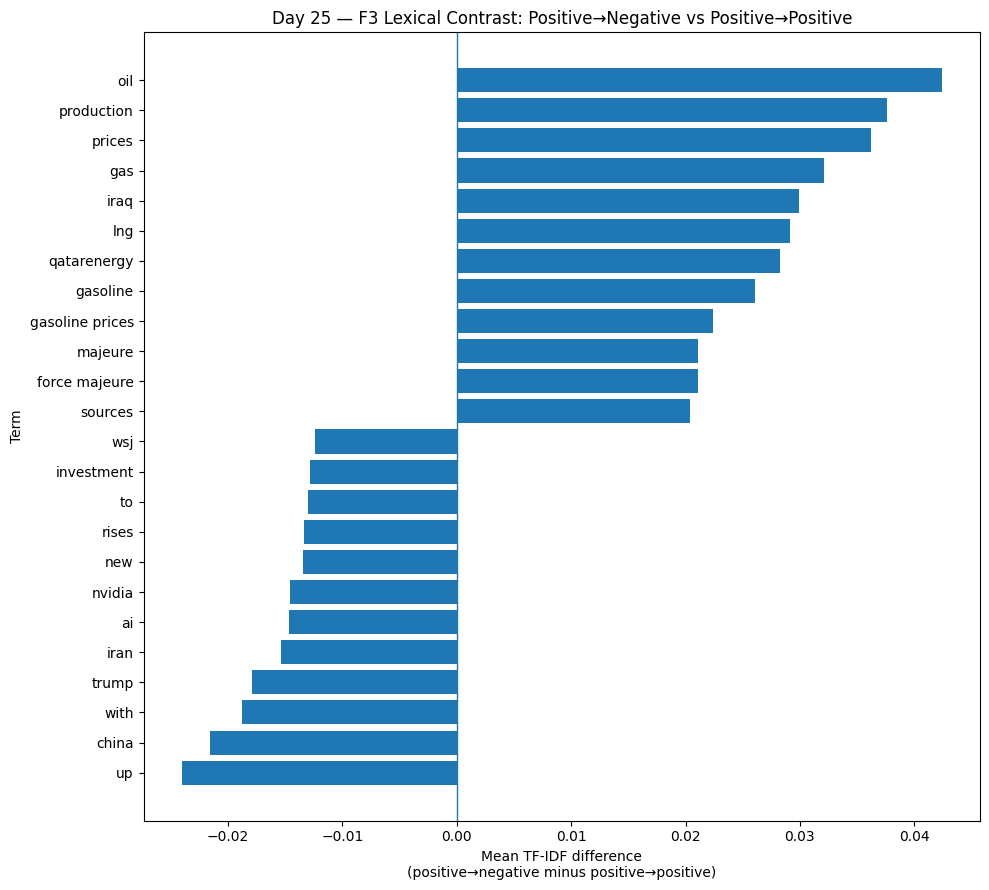

DAY 25 — F3 LEXICAL CONTRAST FIGURE
TERMS ENRICHED IN POSITIVE → NEGATIVE
------------------------------------------------------------------------------------------------------------------------
           term  mean_tfidf_difference  df_posneg  df_pospos  df_rate_posneg  df_rate_pospos
            oil                 0.0424         38         42          0.3654          0.1214
     production                 0.0377         19          7          0.1827          0.0202
         prices                 0.0362         17         11          0.1635          0.0318
            gas                 0.0321         11          6          0.1058          0.0173
           iraq                 0.0299         13          4          0.1250          0.0116
            lng                 0.0291          9          2          0.0865          0.0058
    qatarenergy                 0.0283          6          2          0.0577          0.0058
       gasoline                 0.0261          7          2 

In [23]:
# ============================================================
# DAY 25 — CELL 19
# TOP F3 LEXICAL CONTRAST FIGURE
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Select interpretable top terms
# ------------------------------------------------------------

TOP_TERMS_PER_DIRECTION = 12

top_error_terms = (
    lexical_contrast[
        lexical_contrast["mean_tfidf_difference"] > 0
    ]
    .nlargest(
        TOP_TERMS_PER_DIRECTION,
        "mean_tfidf_difference",
    )
    .copy()
)

top_correct_terms = (
    lexical_contrast[
        lexical_contrast["mean_tfidf_difference"] < 0
    ]
    .nsmallest(
        TOP_TERMS_PER_DIRECTION,
        "mean_tfidf_difference",
    )
    .copy()
)

# Combine for one diverging figure
plot_terms = pd.concat(
    [
        top_correct_terms,
        top_error_terms,
    ],
    ignore_index=True,
)

plot_terms = (
    plot_terms
    .sort_values(
        "mean_tfidf_difference",
        ascending=True,
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 9)
)

y = np.arange(
    len(plot_terms)
)

ax.barh(
    y,
    plot_terms[
        "mean_tfidf_difference"
    ].values,
)

ax.set_yticks(
    y
)

ax.set_yticklabels(
    plot_terms["term"]
)

ax.axvline(
    0,
    linewidth=1,
)

ax.set_xlabel(
    "Mean TF-IDF difference\n"
    "(positive→negative minus positive→positive)"
)

ax.set_ylabel(
    "Term"
)

ax.set_title(
    "Day 25 — F3 Lexical Contrast: "
    "Positive→Negative vs Positive→Positive"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

LEXICAL_CONTRAST_FIGURE_PATH = (
    DAY25_RESULTS_ROOT
    / "lexical_contrast_f3_posneg_vs_pospos.png"
)

plt.savefig(
    LEXICAL_CONTRAST_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Supporting figure table
# ------------------------------------------------------------

LEXICAL_FIGURE_TABLE_PATH = (
    DAY25_RESULTS_ROOT
    / "lexical_contrast_f3_posneg_vs_pospos_top_terms.csv"
)

plot_terms[
    [
        "term",
        "mean_tfidf_posneg",
        "mean_tfidf_pospos",
        "mean_tfidf_difference",
        "df_posneg",
        "df_pospos",
        "df_rate_posneg",
        "df_rate_pospos",
        "direction",
    ]
].to_csv(
    LEXICAL_FIGURE_TABLE_PATH,
    index=False,
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

figure_checks = {
    "figure_exists":
        LEXICAL_CONTRAST_FIGURE_PATH.exists(),

    "figure_nonempty":
        (
            LEXICAL_CONTRAST_FIGURE_PATH.exists()
            and
            LEXICAL_CONTRAST_FIGURE_PATH.stat().st_size > 0
        ),

    "table_exists":
        LEXICAL_FIGURE_TABLE_PATH.exists(),

    "table_nonempty":
        (
            LEXICAL_FIGURE_TABLE_PATH.exists()
            and
            LEXICAL_FIGURE_TABLE_PATH.stat().st_size > 0
        ),

    "both_directions_present":
        (
            (plot_terms["mean_tfidf_difference"] > 0).any()
            and
            (plot_terms["mean_tfidf_difference"] < 0).any()
        ),
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — F3 LEXICAL CONTRAST FIGURE")
print("=" * 120)

print("TERMS ENRICHED IN POSITIVE → NEGATIVE")
print("-" * 120)

print(
    top_error_terms[
        [
            "term",
            "mean_tfidf_difference",
            "df_posneg",
            "df_pospos",
            "df_rate_posneg",
            "df_rate_pospos",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("-" * 120)
print("TERMS ENRICHED IN POSITIVE → POSITIVE")
print("-" * 120)

print(
    top_correct_terms[
        [
            "term",
            "mean_tfidf_difference",
            "df_posneg",
            "df_pospos",
            "df_rate_posneg",
            "df_rate_pospos",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("-" * 120)

print(
    f"Saved figure : "
    f"{LEXICAL_CONTRAST_FIGURE_PATH}"
)

print(
    f"Saved table  : "
    f"{LEXICAL_FIGURE_TABLE_PATH}"
)

print("-" * 120)

for name, passed in figure_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    figure_checks.values()
):

    failed = [
        name
        for name, passed
        in figure_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Stage 5 lexical figure verification failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    "STATUS: PASS — primary F3 lexical contrast "
    "visualized and saved."
)

print("=" * 120)

In [24]:
# ============================================================
# DAY 25 — CELL 20
# F3 TRUE-POSITIVE VS NEIGHBORING TRUE-POSITIVE
# LEXICAL SHIFT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------------------
# Freeze neighboring positive population
# ------------------------------------------------------------

neighbor_positive = (
    day25_future[
        (day25_future["period"].isin(
            [
                "F2",
                "F3",
                "F4",
            ]
        ))
        &
        (
            day25_future["true_label"]
            == "positive"
        )
    ]
    .copy()
)

expected_positive_counts = {
    "F2": 606,
    "F3": 544,
    "F4": 617,
}

# ------------------------------------------------------------
# Shared TF-IDF vocabulary
# ------------------------------------------------------------

NEIGHBOR_TFIDF_NGRAM_RANGE = (1, 2)
NEIGHBOR_TFIDF_MIN_DF = 5
NEIGHBOR_TFIDF_MAX_DF = 0.95
NEIGHBOR_TFIDF_SUBLINEAR_TF = True

neighbor_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=NEIGHBOR_TFIDF_NGRAM_RANGE,
    min_df=NEIGHBOR_TFIDF_MIN_DF,
    max_df=NEIGHBOR_TFIDF_MAX_DF,
    sublinear_tf=NEIGHBOR_TFIDF_SUBLINEAR_TF,
    norm="l2",
)

X_neighbor = (
    neighbor_vectorizer
    .fit_transform(
        neighbor_positive["text"]
        .astype(str)
        .tolist()
    )
)

neighbor_terms = np.array(
    neighbor_vectorizer
    .get_feature_names_out()
)

neighbor_periods = (
    neighbor_positive["period"]
    .to_numpy()
)

# ------------------------------------------------------------
# Compute period-level TF-IDF / document-frequency statistics
# ------------------------------------------------------------

period_stats = {}

for period in [
    "F2",
    "F3",
    "F4",
]:

    mask = (
        neighbor_periods
        == period
    )

    X_period = (
        X_neighbor[
            mask
        ]
    )

    n_period = int(
        mask.sum()
    )

    mean_tfidf = np.asarray(
        X_period.mean(
            axis=0
        )
    ).ravel()

    document_frequency = np.asarray(
        (
            X_period > 0
        )
        .sum(
            axis=0
        )
    ).ravel()

    document_rate = (
        document_frequency
        / n_period
    )

    period_stats[
        period
    ] = {
        "n":
            n_period,

        "mean_tfidf":
            mean_tfidf,

        "document_frequency":
            document_frequency,

        "document_rate":
            document_rate,
    }

# ------------------------------------------------------------
# Construct F3-vs-neighbor contrast table
# ------------------------------------------------------------

neighbor_contrast_rows = []

for reference_period in [
    "F2",
    "F4",
]:

    mean_diff = (
        period_stats["F3"][
            "mean_tfidf"
        ]
        -
        period_stats[
            reference_period
        ][
            "mean_tfidf"
        ]
    )

    df_rate_diff = (
        period_stats["F3"][
            "document_rate"
        ]
        -
        period_stats[
            reference_period
        ][
            "document_rate"
        ]
    )

    for j, term in enumerate(
        neighbor_terms
    ):

        neighbor_contrast_rows.append(
            {
                "reference_period":
                    reference_period,

                "term":
                    term,

                "f3_mean_tfidf":
                    float(
                        period_stats[
                            "F3"
                        ][
                            "mean_tfidf"
                        ][j]
                    ),

                "reference_mean_tfidf":
                    float(
                        period_stats[
                            reference_period
                        ][
                            "mean_tfidf"
                        ][j]
                    ),

                "mean_tfidf_difference":
                    float(
                        mean_diff[j]
                    ),

                "abs_mean_tfidf_difference":
                    float(
                        abs(
                            mean_diff[j]
                        )
                    ),

                "f3_document_frequency":
                    int(
                        period_stats[
                            "F3"
                        ][
                            "document_frequency"
                        ][j]
                    ),

                "reference_document_frequency":
                    int(
                        period_stats[
                            reference_period
                        ][
                            "document_frequency"
                        ][j]
                    ),

                "f3_document_rate":
                    float(
                        period_stats[
                            "F3"
                        ][
                            "document_rate"
                        ][j]
                    ),

                "reference_document_rate":
                    float(
                        period_stats[
                            reference_period
                        ][
                            "document_rate"
                        ][j]
                    ),

                "document_rate_difference":
                    float(
                        df_rate_diff[j]
                    ),
            }
        )

neighbor_lexical_contrast = pd.DataFrame(
    neighbor_contrast_rows
)

# ------------------------------------------------------------
# Save canonical artifact
# ------------------------------------------------------------

NEIGHBOR_LEXICAL_CONTRAST_PATH = (
    DAY25_RESULTS_ROOT
    / "lexical_contrast_f3_positive_vs_neighbors.csv"
)

neighbor_lexical_contrast.to_csv(
    NEIGHBOR_LEXICAL_CONTRAST_PATH,
    index=False,
)

# ------------------------------------------------------------
# Inspect previously identified F3 error-cohort terms
# ------------------------------------------------------------

error_signature_terms = [
    "oil",
    "production",
    "prices",
    "gas",
    "iraq",
    "lng",
    "qatarenergy",
    "gasoline",
    "gasoline prices",
    "force majeure",
    "majeure",
    "crude",
    "cuts",
    "hormuz",
    "oil production",
]

signature_neighbor_table = (
    neighbor_lexical_contrast[
        neighbor_lexical_contrast[
            "term"
        ].isin(
            error_signature_terms
        )
    ]
    .copy()
    .sort_values(
        [
            "reference_period",
            "mean_tfidf_difference",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

# ------------------------------------------------------------
# Top F3-enriched terms by comparison
# ------------------------------------------------------------

top_neighbor_tables = {}

TOP_NEIGHBOR_TERMS = 15

for reference_period in [
    "F2",
    "F4",
]:

    temp = (
        neighbor_lexical_contrast[
            neighbor_lexical_contrast[
                "reference_period"
            ]
            == reference_period
        ]
        .copy()
    )

    top_neighbor_tables[
        reference_period
    ] = (
        temp[
            temp[
                "mean_tfidf_difference"
            ]
            > 0
        ]
        .nlargest(
            TOP_NEIGHBOR_TERMS,
            "mean_tfidf_difference",
        )
    )

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

neighbor_checks = {
    "f2_positive_n_606":
        period_stats[
            "F2"
        ]["n"] == 606,

    "f3_positive_n_544":
        period_stats[
            "F3"
        ]["n"] == 544,

    "f4_positive_n_617":
        period_stats[
            "F4"
        ]["n"] == 617,

    "combined_positive_n_1767":
        len(
            neighbor_positive
        ) == 1767,

    "vocabulary_nonempty":
        len(
            neighbor_terms
        ) > 0,

    "contrast_has_f2_and_f4":
        set(
            neighbor_lexical_contrast[
                "reference_period"
            ].unique()
        )
        == {
            "F2",
            "F4",
        },

    "no_missing_statistics":
        neighbor_lexical_contrast[
            [
                "mean_tfidf_difference",
                "document_rate_difference",
            ]
        ]
        .notna()
        .all()
        .all(),
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — F3 POSITIVE VS NEIGHBORING POSITIVE LEXICAL SHIFT")
print("=" * 120)

print(
    f"F2 true positives : "
    f"{period_stats['F2']['n']}"
)

print(
    f"F3 true positives : "
    f"{period_stats['F3']['n']}"
)

print(
    f"F4 true positives : "
    f"{period_stats['F4']['n']}"
)

print(
    f"Shared vocabulary : "
    f"{len(neighbor_terms):,}"
)

print("-" * 120)
print("TOP TERMS ENRICHED IN F3 POSITIVES VS F2 POSITIVES")
print("-" * 120)

print(
    top_neighbor_tables[
        "F2"
    ][
        [
            "term",
            "mean_tfidf_difference",
            "f3_document_frequency",
            "reference_document_frequency",
            "f3_document_rate",
            "reference_document_rate",
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("-" * 120)
print("TOP TERMS ENRICHED IN F3 POSITIVES VS F4 POSITIVES")
print("-" * 120)

print(
    top_neighbor_tables[
        "F4"
    ][
        [
            "term",
            "mean_tfidf_difference",
            "f3_document_frequency",
            "reference_document_frequency",
            "f3_document_rate",
            "reference_document_rate",
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("-" * 120)
print("ERROR-COHORT ENERGY / SUPPLY TERMS IN F3 VS NEIGHBOR COMPARISONS")
print("-" * 120)

print(
    signature_neighbor_table[
        [
            "reference_period",
            "term",
            "mean_tfidf_difference",
            "f3_document_frequency",
            "reference_document_frequency",
            "f3_document_rate",
            "reference_document_rate",
            "document_rate_difference",
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("-" * 120)
print("LEXICAL SHIFT INTEGRITY CHECKS")
print("-" * 120)

for name, passed in (
    neighbor_checks.items()
):

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    neighbor_checks.values()
):

    failed = [
        name
        for name, passed
        in neighbor_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Neighbor lexical contrast integrity failure: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: "
    f"{NEIGHBOR_LEXICAL_CONTRAST_PATH}"
)

print(
    "STATUS: PASS — F3 positive lexical composition "
    "compared against neighboring F2/F4 positives."
)

print("=" * 120)

DAY 25 — F3 POSITIVE VS NEIGHBORING POSITIVE LEXICAL SHIFT
F2 true positives : 606
F3 true positives : 544
F4 true positives : 617
Shared vocabulary : 1,477
------------------------------------------------------------------------------------------------------------------------
TOP TERMS ENRICHED IN F3 POSITIVES VS F2 POSITIVES
------------------------------------------------------------------------------------------------------------------------
      term  mean_tfidf_difference  f3_document_frequency  reference_document_frequency  f3_document_rate  reference_document_rate
       oil                 0.0244                     95                            31            0.1746                   0.0512
      iran                 0.0148                     46                             5            0.0846                   0.0083
       the                 0.0144                    104                            66            0.1912                   0.1089
    prices                 0.0

## Stage 6 — Optional Topic / Embedding Audit

**Status: Skipped by design.**

Stages 2–5 already identified a coherent and reproducible lexical structure associated with the F3 residual failure:

- F3 exhibits a broader energy / commodity / supply-disruption lexical shift relative to both F2 and F4;
- the same lexical structure is disproportionately concentrated in the F3 positive → negative error cohort.

Because the primary lightweight diagnostics already provide a clear signal, additional clustering, sentence embeddings, UMAP, or t-SNE would add exploratory complexity without materially improving the current mechanism classification.

## Stage 7 — Joint Source × Lexical/Error Concentration Analysis

### Scientific Question

Does the F3 lexical error signature persist after conditioning on source?

The earlier stages established that:

- F3 has a modest but real source-composition shift;
- F3 positive recall declines within major common sources;
- F3 positives exhibit an energy / commodity / supply-disruption lexical shift;
- the same lexical structure is especially concentrated among positive → negative errors.

This stage tests whether the lexical signal survives within-source conditioning.

If the lexical contrast disappears after conditioning on source, the mechanism is more consistent with source mediation.

If the same lexical structure persists within major common sources, a broader lexical/topic mechanism is supported beyond pure source composition.

In [25]:
# ============================================================
# DAY 25 — CELL 21
# WITHIN-SOURCE LEXICAL PERSISTENCE AUDIT
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Frozen lexical vocabulary from Stage 5
# ------------------------------------------------------------

if "vectorizer" not in globals():
    raise RuntimeError(
        "Stage 5 frozen TF-IDF vectorizer is unavailable."
    )

frozen_terms = np.array(
    vectorizer.get_feature_names_out()
)

# ------------------------------------------------------------
# Pre-specified major F3 sources
# ------------------------------------------------------------

major_f3_sources = [
    "firstsquaw",
    "WalterBloomberg",
    "MonitoringSituation",
]

# Minimum cohort support for interpretation
MIN_WITHIN_SOURCE_COHORT_N = 8

# ------------------------------------------------------------
# Error-signature terms identified before source conditioning
# ------------------------------------------------------------

energy_signature_terms = [
    "oil",
    "production",
    "prices",
    "gas",
    "iraq",
    "lng",
    "qatarenergy",
    "gasoline",
    "gasoline prices",
    "force majeure",
    "majeure",
    "crude",
    "cuts",
    "hormuz",
    "oil production",
]

# ------------------------------------------------------------
# Compute within-source P→N vs P→P contrasts
# using the frozen Stage 5 vocabulary
# ------------------------------------------------------------

within_source_rows = []
within_source_summary_rows = []

for source in major_f3_sources:

    source_df = (
        f3_positive_cohorts[
            (
                f3_positive_cohorts["source"]
                == source
            )
            &
            (
                f3_positive_cohorts["cohort"]
                .isin(
                    [
                        "positive_to_negative",
                        "positive_to_positive",
                    ]
                )
            )
        ]
        .copy()
    )

    source_posneg = (
        source_df[
            source_df["cohort"]
            == "positive_to_negative"
        ]
    )

    source_pospos = (
        source_df[
            source_df["cohort"]
            == "positive_to_positive"
        ]
    )

    n_posneg = len(source_posneg)
    n_pospos = len(source_pospos)

    stable = (
        n_posneg >= MIN_WITHIN_SOURCE_COHORT_N
        and
        n_pospos >= MIN_WITHIN_SOURCE_COHORT_N
    )

    # Transform using frozen global Stage 5 vocabulary.
    X_source = vectorizer.transform(
        source_df["text"]
        .astype(str)
        .tolist()
    )

    labels_source = (
        source_df["cohort"]
        .to_numpy()
    )

    mask_neg = (
        labels_source
        == "positive_to_negative"
    )

    mask_pos = (
        labels_source
        == "positive_to_positive"
    )

    X_neg = X_source[
        mask_neg
    ]

    X_pos = X_source[
        mask_pos
    ]

    mean_neg = np.asarray(
        X_neg.mean(axis=0)
    ).ravel()

    mean_pos = np.asarray(
        X_pos.mean(axis=0)
    ).ravel()

    mean_diff = (
        mean_neg
        - mean_pos
    )

    df_neg = np.asarray(
        (X_neg > 0)
        .sum(axis=0)
    ).ravel()

    df_pos = np.asarray(
        (X_pos > 0)
        .sum(axis=0)
    ).ravel()

    df_rate_neg = (
        df_neg / n_posneg
        if n_posneg > 0
        else np.full(
            len(frozen_terms),
            np.nan,
        )
    )

    df_rate_pos = (
        df_pos / n_pospos
        if n_pospos > 0
        else np.full(
            len(frozen_terms),
            np.nan,
        )
    )

    source_term_table = pd.DataFrame(
        {
            "source": source,
            "term": frozen_terms,

            "n_posneg": n_posneg,
            "n_pospos": n_pospos,

            "mean_tfidf_posneg":
                mean_neg,

            "mean_tfidf_pospos":
                mean_pos,

            "mean_tfidf_difference":
                mean_diff,

            "df_posneg":
                df_neg.astype(int),

            "df_pospos":
                df_pos.astype(int),

            "df_rate_posneg":
                df_rate_neg,

            "df_rate_pospos":
                df_rate_pos,

            "stable_for_interpretation":
                stable,
        }
    )

    within_source_rows.append(
        source_term_table
    )

    # --------------------------------------------------------
    # Summarize the pre-identified energy signature
    # --------------------------------------------------------

    signature_table = (
        source_term_table[
            source_term_table[
                "term"
            ].isin(
                energy_signature_terms
            )
        ]
        .copy()
    )

    n_signature_available = int(
        len(
            signature_table
        )
    )

    n_signature_positive = int(
        (
            signature_table[
                "mean_tfidf_difference"
            ]
            > 0
        ).sum()
    )

    mean_signature_difference = float(
        signature_table[
            "mean_tfidf_difference"
        ].mean()
    )

    median_signature_difference = float(
        signature_table[
            "mean_tfidf_difference"
        ].median()
    )

    # strongest positive within-source terms
    top_source_terms = (
        source_term_table[
            source_term_table[
                "mean_tfidf_difference"
            ]
            > 0
        ]
        .nlargest(
            10,
            "mean_tfidf_difference",
        )
    )

    top_source_term_names = (
        top_source_terms["term"]
        .tolist()
    )

    within_source_summary_rows.append(
        {
            "source":
                source,

            "n_posneg":
                n_posneg,

            "n_pospos":
                n_pospos,

            "stable_for_interpretation":
                stable,

            "energy_signature_terms_available":
                n_signature_available,

            "energy_signature_terms_positive":
                n_signature_positive,

            "energy_signature_positive_fraction":
                (
                    n_signature_positive
                    / n_signature_available
                    if n_signature_available > 0
                    else np.nan
                ),

            "mean_energy_signature_tfidf_difference":
                mean_signature_difference,

            "median_energy_signature_tfidf_difference":
                median_signature_difference,

            "top_10_posneg_enriched_terms":
                " | ".join(
                    top_source_term_names
                ),
        }
    )


within_source_lexical = pd.concat(
    within_source_rows,
    ignore_index=True,
)

within_source_lexical_summary = pd.DataFrame(
    within_source_summary_rows
)

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------

WITHIN_SOURCE_LEXICAL_PATH = (
    DAY25_RESULTS_ROOT
    / "within_source_lexical_contrast.csv"
)

WITHIN_SOURCE_LEXICAL_SUMMARY_PATH = (
    DAY25_RESULTS_ROOT
    / "within_source_lexical_summary.csv"
)

within_source_lexical.to_csv(
    WITHIN_SOURCE_LEXICAL_PATH,
    index=False,
)

within_source_lexical_summary.to_csv(
    WITHIN_SOURCE_LEXICAL_SUMMARY_PATH,
    index=False,
)

# ------------------------------------------------------------
# Display signature terms
# ------------------------------------------------------------

signature_display = (
    within_source_lexical[
        within_source_lexical[
            "term"
        ].isin(
            energy_signature_terms
        )
    ]
    .copy()
    .sort_values(
        [
            "source",
            "mean_tfidf_difference",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

within_source_checks = {
    "three_major_sources":
        len(
            within_source_lexical_summary
        ) == 3,

    "firstsquaw_posneg_69":
        int(
            within_source_lexical_summary.loc[
                within_source_lexical_summary[
                    "source"
                ]
                == "firstsquaw",
                "n_posneg",
            ].iloc[0]
        )
        == 69,

    "walter_posneg_19":
        int(
            within_source_lexical_summary.loc[
                within_source_lexical_summary[
                    "source"
                ]
                == "WalterBloomberg",
                "n_posneg",
            ].iloc[0]
        )
        == 19,

    "monitoring_posneg_16":
        int(
            within_source_lexical_summary.loc[
                within_source_lexical_summary[
                    "source"
                ]
                == "MonitoringSituation",
                "n_posneg",
            ].iloc[0]
        )
        == 16,

    "all_sources_stable":
        within_source_lexical_summary[
            "stable_for_interpretation"
        ].all(),

    "no_missing_signature_summary":
        within_source_lexical_summary[
            [
                "energy_signature_positive_fraction",
                "mean_energy_signature_tfidf_difference",
            ]
        ]
        .notna()
        .all()
        .all(),
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — WITHIN-SOURCE LEXICAL PERSISTENCE AUDIT")
print("=" * 120)

print("SOURCE-LEVEL SUMMARY")
print("-" * 120)

print(
    within_source_lexical_summary[
        [
            "source",
            "n_posneg",
            "n_pospos",
            "stable_for_interpretation",
            "energy_signature_terms_available",
            "energy_signature_terms_positive",
            "energy_signature_positive_fraction",
            "mean_energy_signature_tfidf_difference",
            "median_energy_signature_tfidf_difference",
        ]
    ]
    .round(
        {
            "energy_signature_positive_fraction": 4,
            "mean_energy_signature_tfidf_difference": 5,
            "median_energy_signature_tfidf_difference": 5,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("ENERGY / SUPPLY SIGNATURE WITHIN SOURCE")
print("-" * 120)

print(
    signature_display[
        [
            "source",
            "term",
            "mean_tfidf_difference",
            "df_posneg",
            "df_pospos",
            "df_rate_posneg",
            "df_rate_pospos",
        ]
    ]
    .round(
        {
            "mean_tfidf_difference": 5,
            "df_rate_posneg": 4,
            "df_rate_pospos": 4,
        }
    )
    .to_string(
        index=False
    )
)

print("-" * 120)
print("TOP POSNEG-ENRICHED TERMS WITHIN SOURCE")
print("-" * 120)

for _, row in (
    within_source_lexical_summary
    .iterrows()
):

    print(
        f"{row['source']:<24}: "
        f"{row['top_10_posneg_enriched_terms']}"
    )

print("-" * 120)
print("INTEGRITY CHECKS")
print("-" * 120)

for name, passed in (
    within_source_checks.items()
):

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    within_source_checks.values()
):

    failed = [
        name
        for name, passed
        in within_source_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Within-source lexical audit failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: {WITHIN_SOURCE_LEXICAL_PATH}"
)

print(
    f"Saved: {WITHIN_SOURCE_LEXICAL_SUMMARY_PATH}"
)

print(
    "STATUS: PASS — within-source lexical persistence "
    "audited using the frozen Stage 5 vocabulary."
)

print("=" * 120)

DAY 25 — WITHIN-SOURCE LEXICAL PERSISTENCE AUDIT
SOURCE-LEVEL SUMMARY
------------------------------------------------------------------------------------------------------------------------
             source  n_posneg  n_pospos  stable_for_interpretation  energy_signature_terms_available  energy_signature_terms_positive  energy_signature_positive_fraction  mean_energy_signature_tfidf_difference  median_energy_signature_tfidf_difference
         firstsquaw        69       293                       True                                15                               14                              0.9333                                 0.02397                                   0.02781
    WalterBloomberg        19        38                       True                                15                               12                              0.8000                                 0.02908                                   0.02570
MonitoringSituation        16         8              

## Stage 8 — Scientific Integration and Mechanism Classification

### Integration Goal

Combine the prior-shift, source-composition, source-conditioned performance, error-cohort, and lexical evidence into a single reproducible mechanism assessment.

The final mechanism classification must distinguish between:

- **A — primarily source-composition associated**
- **B — primarily lexical/topic associated and persistent within sources**
- **C — mixed source + lexical association**
- **D — unresolved with current artifacts**

The classification will be based on converging evidence rather than any single statistic.

Causal language is not permitted. Conclusions will use evidence-calibrated wording such as:

- “associated with”;
- “concentrated in”;
- “consistent with”;
- “persists after conditioning on source.”

In [26]:
# ============================================================
# DAY 25 — CELL 22
# SCIENTIFIC MECHANISM EVIDENCE INTEGRATION
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Extract key quantitative evidence
# ------------------------------------------------------------

# Stage 1 — prior shift
f3_positive_shift_vs_v = float(
    f3_prior_shift.loc[
        (
            f3_prior_shift["reference_period"] == "V"
        )
        &
        (
            f3_prior_shift["label"] == "positive"
        ),
        "true_shift_pp",
    ].iloc[0]
)

f3_negative_shift_vs_v = float(
    f3_prior_shift.loc[
        (
            f3_prior_shift["reference_period"] == "V"
        )
        &
        (
            f3_prior_shift["label"] == "negative"
        ),
        "true_shift_pp",
    ].iloc[0]
)

# Stage 2 — source composition
overall_tvd_vs_v = float(
    source_distance_summary.loc[
        (
            source_distance_summary["subset"]
            == "all_observations"
        )
        &
        (
            source_distance_summary["reference_period"]
            == "V"
        ),
        "total_variation_distance",
    ].iloc[0]
)

positive_tvd_vs_v = float(
    source_distance_summary.loc[
        (
            source_distance_summary["subset"]
            == "true_positive"
        )
        &
        (
            source_distance_summary["reference_period"]
            == "V"
        ),
        "total_variation_distance",
    ].iloc[0]
)

monitoring_positive_shift_vs_v = float(
    source_shift_summary.loc[
        (
            source_shift_summary["subset"]
            == "true_positive"
        )
        &
        (
            source_shift_summary["reference_period"]
            == "V"
        )
        &
        (
            source_shift_summary["source"]
            == "MonitoringSituation"
        ),
        "shift_pp",
    ].iloc[0]
)

# Stage 3 — source-conditioned performance
firstsquaw_bootstrap = (
    source_recall_bootstrap[
        (
            source_recall_bootstrap["source"]
            == "firstsquaw"
        )
        &
        (
            source_recall_bootstrap["reference_period"]
            == "V"
        )
    ]
    .iloc[0]
)

walter_bootstrap = (
    source_recall_bootstrap[
        (
            source_recall_bootstrap["source"]
            == "WalterBloomberg"
        )
        &
        (
            source_recall_bootstrap["reference_period"]
            == "V"
        )
    ]
    .iloc[0]
)

monitoring_bootstrap = (
    source_recall_bootstrap[
        (
            source_recall_bootstrap["source"]
            == "MonitoringSituation"
        )
        &
        (
            source_recall_bootstrap["reference_period"]
            == "F4"
        )
    ]
    .iloc[0]
)

# Stage 4/5 — error cohort
f3_posneg_n = int(
    (
        f3_positive_cohorts["cohort"]
        == "positive_to_negative"
    ).sum()
)

f3_pospos_n = int(
    (
        f3_positive_cohorts["cohort"]
        == "positive_to_positive"
    ).sum()
)

# Stage 5 — lexical signature
oil_row = lexical_contrast[
    lexical_contrast["term"] == "oil"
].iloc[0]

production_row = lexical_contrast[
    lexical_contrast["term"] == "production"
].iloc[0]

prices_row = lexical_contrast[
    lexical_contrast["term"] == "prices"
].iloc[0]

# Stage 7 — within-source lexical persistence
firstsquaw_lex = (
    within_source_lexical_summary[
        within_source_lexical_summary["source"]
        == "firstsquaw"
    ]
    .iloc[0]
)

walter_lex = (
    within_source_lexical_summary[
        within_source_lexical_summary["source"]
        == "WalterBloomberg"
    ]
    .iloc[0]
)

monitoring_lex = (
    within_source_lexical_summary[
        within_source_lexical_summary["source"]
        == "MonitoringSituation"
    ]
    .iloc[0]
)

# ------------------------------------------------------------
# Build evidence table
# ------------------------------------------------------------

mechanism_evidence = pd.DataFrame(
    [
        {
            "mechanism":
                "H1_source_composition",

            "evidence_status":
                "PARTIAL_SUPPORT",

            "key_evidence":
                (
                    f"Overall F3-vs-V source TVD={overall_tvd_vs_v:.4f}; "
                    f"positive-only TVD={positive_tvd_vs_v:.4f}; "
                    f"MonitoringSituation positive share shift="
                    f"{monitoring_positive_shift_vs_v:+.2f} pp."
                ),

            "counter_evidence":
                (
                    "F3 positive-recall degradation persists within "
                    "firstsquaw and WalterBloomberg, weakening a pure "
                    "source-composition explanation."
                ),

            "interpretation":
                (
                    "Source composition contributes to the residual "
                    "failure but is not sufficient by itself."
                ),
        },

        {
            "mechanism":
                "H2_class_prior_shift",

            "evidence_status":
                "SUPPORTED_BUT_INSUFFICIENT",

            "key_evidence":
                (
                    f"F3 positive prevalence vs V="
                    f"{f3_positive_shift_vs_v:+.2f} pp; "
                    f"negative prevalence vs V="
                    f"{f3_negative_shift_vs_v:+.2f} pp."
                ),

            "counter_evidence":
                (
                    "A class-prior shift cannot explain degradation "
                    "conditional on the true-positive class."
                ),

            "interpretation":
                (
                    "Class composition contributes to aggregate metric "
                    "differences but does not explain the positive-recall "
                    "collapse."
                ),
        },

        {
            "mechanism":
                "H3_broader_lexical_topic_shift",

            "evidence_status":
                "SUPPORTED",

            "key_evidence":
                (
                    "F3 true positives show enrichment of oil, gas, "
                    "production, prices, supply-disruption, and related "
                    "terms relative to both F2 and F4 positives."
                ),

            "counter_evidence":
                (
                    "Not every energy-related term is uniquely elevated "
                    "in F3; lexical contrasts are associative rather than "
                    "causal."
                ),

            "interpretation":
                (
                    "F3 contains a broader energy/commodity/supply lexical "
                    "shift relative to neighboring periods."
                ),
        },

        {
            "mechanism":
                "H4_error_cohort_lexical_structure",

            "evidence_status":
                "STRONGLY_SUPPORTED",

            "key_evidence":
                (
                    f"Frozen cohorts: P→N n={f3_posneg_n}, "
                    f"P→P n={f3_pospos_n}. "
                    f"'oil' document rates="
                    f"{oil_row['df_rate_posneg']:.3f} vs "
                    f"{oil_row['df_rate_pospos']:.3f}; "
                    f"'production'="
                    f"{production_row['df_rate_posneg']:.3f} vs "
                    f"{production_row['df_rate_pospos']:.3f}; "
                    f"'prices'="
                    f"{prices_row['df_rate_posneg']:.3f} vs "
                    f"{prices_row['df_rate_pospos']:.3f}."
                ),

            "counter_evidence":
                (
                    "TF-IDF establishes lexical association, not semantic "
                    "or causal mechanism."
                ),

            "interpretation":
                (
                    "The F3 positive→negative failures form a coherent "
                    "energy/supply-related lexical cohort."
                ),
        },

        {
            "mechanism":
                "H5_mixed_source_lexical",

            "evidence_status":
                "STRONGLY_SUPPORTED",

            "key_evidence":
                (
                    "The energy/supply signature persists within all three "
                    "major F3 sources: positive signature fractions="
                    f"{firstsquaw_lex['energy_signature_positive_fraction']:.3f} "
                    f"(firstsquaw), "
                    f"{walter_lex['energy_signature_positive_fraction']:.3f} "
                    f"(WalterBloomberg), "
                    f"{monitoring_lex['energy_signature_positive_fraction']:.3f} "
                    f"(MonitoringSituation)."
                ),

            "counter_evidence":
                (
                    "Source composition still changes modestly in F3, so "
                    "the lexical mechanism should not be described as "
                    "completely source-independent."
                ),

            "interpretation":
                (
                    "A mixed mechanism is most consistent with the evidence, "
                    "with lexical/topic shift appearing dominant and source "
                    "composition contributing secondarily."
                ),
        },
    ]
)

# ------------------------------------------------------------
# Add source-conditioned bootstrap evidence separately
# ------------------------------------------------------------

source_bootstrap_summary = pd.DataFrame(
    [
        {
            "source": "firstsquaw",
            "comparison": "F3_minus_V_positive_recall",
            "delta":
                float(
                    firstsquaw_bootstrap[
                        "delta_f3_minus_reference"
                    ]
                ),
            "ci_low_95":
                float(
                    firstsquaw_bootstrap[
                        "ci_low_95"
                    ]
                ),
            "ci_high_95":
                float(
                    firstsquaw_bootstrap[
                        "ci_high_95"
                    ]
                ),
        },
        {
            "source": "WalterBloomberg",
            "comparison": "F3_minus_V_positive_recall",
            "delta":
                float(
                    walter_bootstrap[
                        "delta_f3_minus_reference"
                    ]
                ),
            "ci_low_95":
                float(
                    walter_bootstrap[
                        "ci_low_95"
                    ]
                ),
            "ci_high_95":
                float(
                    walter_bootstrap[
                        "ci_high_95"
                    ]
                ),
        },
        {
            "source": "MonitoringSituation",
            "comparison": "F3_minus_F4_positive_recall",
            "delta":
                float(
                    monitoring_bootstrap[
                        "delta_f3_minus_reference"
                    ]
                ),
            "ci_low_95":
                float(
                    monitoring_bootstrap[
                        "ci_low_95"
                    ]
                ),
            "ci_high_95":
                float(
                    monitoring_bootstrap[
                        "ci_high_95"
                    ]
                ),
        },
    ]
)

# ------------------------------------------------------------
# Final mechanism classification
# ------------------------------------------------------------

DAY25_MECHANISM_CLASS = "C"

DAY25_MECHANISM_LABEL = (
    "mixed source + lexical association"
)

DAY25_MECHANISM_QUALIFIER = (
    "Lexical/topic shift appears dominant, while source "
    "composition contributes secondarily."
)

# ------------------------------------------------------------
# Save canonical mechanism evidence
# ------------------------------------------------------------

MECHANISM_EVIDENCE_PATH = (
    DAY25_RESULTS_ROOT
    / "day25_mechanism_evidence.csv"
)

SOURCE_BOOTSTRAP_SUMMARY_PATH = (
    DAY25_RESULTS_ROOT
    / "day25_source_bootstrap_summary.csv"
)

mechanism_evidence.to_csv(
    MECHANISM_EVIDENCE_PATH,
    index=False,
)

source_bootstrap_summary.to_csv(
    SOURCE_BOOTSTRAP_SUMMARY_PATH,
    index=False,
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

integration_checks = {
    "five_hypotheses_present":
        len(mechanism_evidence) == 5,

    "mechanism_class_C":
        DAY25_MECHANISM_CLASS == "C",

    "all_evidence_status_nonmissing":
        mechanism_evidence[
            "evidence_status"
        ].notna().all(),

    "all_interpretations_nonmissing":
        mechanism_evidence[
            "interpretation"
        ].notna().all(),

    "source_bootstrap_three_rows":
        len(
            source_bootstrap_summary
        ) == 3,

    "mechanism_evidence_saved":
        MECHANISM_EVIDENCE_PATH.exists(),

    "source_bootstrap_summary_saved":
        SOURCE_BOOTSTRAP_SUMMARY_PATH.exists(),
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — SCIENTIFIC MECHANISM EVIDENCE INTEGRATION")
print("=" * 120)

print(
    mechanism_evidence[
        [
            "mechanism",
            "evidence_status",
            "interpretation",
        ]
    ]
    .to_string(
        index=False
    )
)

print("-" * 120)
print("SOURCE-CONDITIONED BOOTSTRAP ANCHORS")
print("-" * 120)

print(
    source_bootstrap_summary
    .round(4)
    .to_string(
        index=False
    )
)

print("-" * 120)
print("MECHANISM CLASSIFICATION")
print("-" * 120)

print(
    f"Class      : "
    f"{DAY25_MECHANISM_CLASS}"
)

print(
    f"Label      : "
    f"{DAY25_MECHANISM_LABEL}"
)

print(
    f"Qualifier  : "
    f"{DAY25_MECHANISM_QUALIFIER}"
)

print("-" * 120)
print("INTEGRATION CHECKS")
print("-" * 120)

for name, passed in (
    integration_checks.items()
):

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    integration_checks.values()
):

    failed = [
        name
        for name, passed
        in integration_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Day25 mechanism integration failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved: {MECHANISM_EVIDENCE_PATH}"
)

print(
    f"Saved: {SOURCE_BOOTSTRAP_SUMMARY_PATH}"
)

print(
    "STATUS: PASS — Day25 mechanism evidence integrated "
    "and provisional classification frozen."
)

print("=" * 120)

DAY 25 — SCIENTIFIC MECHANISM EVIDENCE INTEGRATION
                        mechanism            evidence_status                                                                                                                                       interpretation
            H1_source_composition            PARTIAL_SUPPORT                                                              Source composition contributes to the residual failure but is not sufficient by itself.
             H2_class_prior_shift SUPPORTED_BUT_INSUFFICIENT                                     Class composition contributes to aggregate metric differences but does not explain the positive-recall collapse.
   H3_broader_lexical_topic_shift                  SUPPORTED                                                         F3 contains a broader energy/commodity/supply lexical shift relative to neighboring periods.
H4_error_cohort_lexical_structure         STRONGLY_SUPPORTED                                                 

In [27]:
# ============================================================
# DAY 25 — CELL 23
# FINAL SCIENTIFIC SUMMARY AND CONCLUSION
# ============================================================

import json
from datetime import datetime, timezone

# ------------------------------------------------------------
# Final evidence-calibrated conclusion
# ------------------------------------------------------------

day25_scientific_conclusion = (
    "Day 25 identifies the residual F3 positive-sentiment failure as "
    "most consistent with a mixed source + lexical association. "
    "F3 exhibits a material class-prior shift and a modest source-composition "
    "shift, including increased representation of MonitoringSituation, but "
    "these factors are insufficient to explain the failure by themselves. "
    "Positive recall declines persist within major common sources, including "
    "firstsquaw and WalterBloomberg. In parallel, F3 true-positive texts show "
    "a broader energy/commodity/supply-disruption lexical shift relative to "
    "neighboring F2 and F4 periods, and this lexical structure is especially "
    "concentrated among the 104 positive→negative errors. The same lexical "
    "signature persists after conditioning on the three major F3 sources. "
    "Therefore, the residual failure is associated primarily with a lexical/"
    "topic shift, with source composition contributing secondarily. "
    "These results establish association and concentration, not causal mechanism."
)

# ------------------------------------------------------------
# Final scientific summary
# ------------------------------------------------------------

day25_final_summary = {
    "day": 25,

    "status": "SCIENTIFIC_ANALYSIS_COMPLETE",

    "primary_question": (
        "What observable distributional mechanism is associated with "
        "the residual F3 positive-class failure after historical optimization?"
    ),

    "final_mechanism_class": {
        "class": DAY25_MECHANISM_CLASS,
        "label": DAY25_MECHANISM_LABEL,
        "qualifier": DAY25_MECHANISM_QUALIFIER,
    },

    "key_findings": {
        "class_prior_shift": {
            "status": "SUPPORTED_BUT_INSUFFICIENT",
            "f3_positive_prevalence_shift_vs_validation_pp":
                float(f3_positive_shift_vs_v),
            "f3_negative_prevalence_shift_vs_validation_pp":
                float(f3_negative_shift_vs_v),
        },

        "source_composition_shift": {
            "status": "PARTIAL_SUPPORT",
            "overall_f3_vs_validation_tvd":
                float(overall_tvd_vs_v),
            "positive_only_f3_vs_validation_tvd":
                float(positive_tvd_vs_v),
            "monitoring_situation_positive_share_shift_vs_validation_pp":
                float(monitoring_positive_shift_vs_v),
        },

        "source_conditioned_failure": {
            "status": "SUPPORTED",
            "firstsquaw_f3_minus_validation_positive_recall": {
                "delta":
                    float(
                        firstsquaw_bootstrap[
                            "delta_f3_minus_reference"
                        ]
                    ),
                "ci_low_95":
                    float(
                        firstsquaw_bootstrap[
                            "ci_low_95"
                        ]
                    ),
                "ci_high_95":
                    float(
                        firstsquaw_bootstrap[
                            "ci_high_95"
                        ]
                    ),
            },
            "walter_bloomberg_f3_minus_validation_positive_recall": {
                "delta":
                    float(
                        walter_bootstrap[
                            "delta_f3_minus_reference"
                        ]
                    ),
                "ci_low_95":
                    float(
                        walter_bootstrap[
                            "ci_low_95"
                        ]
                    ),
                "ci_high_95":
                    float(
                        walter_bootstrap[
                            "ci_high_95"
                        ]
                    ),
            },
            "monitoring_situation_f3_minus_f4_positive_recall": {
                "delta":
                    float(
                        monitoring_bootstrap[
                            "delta_f3_minus_reference"
                        ]
                    ),
                "ci_low_95":
                    float(
                        monitoring_bootstrap[
                            "ci_low_95"
                        ]
                    ),
                "ci_high_95":
                    float(
                        monitoring_bootstrap[
                            "ci_high_95"
                        ]
                    ),
            },
        },

        "f3_positive_error_cohort": {
            "positive_to_positive": 346,
            "positive_to_negative": 104,
            "positive_to_neutral": 94,
        },

        "lexical_shift": {
            "status": "STRONGLY_SUPPORTED",
            "dominant_theme": (
                "energy / commodity / supply-disruption language"
            ),
            "representative_terms": [
                "oil",
                "production",
                "prices",
                "gas",
                "crude",
                "gasoline",
                "force majeure",
                "qatarenergy",
                "iraq",
                "lng",
            ],
            "broader_f3_shift_vs_neighbors": True,
            "error_cohort_enrichment": True,
        },

        "within_source_lexical_persistence": {
            "status": "STRONGLY_SUPPORTED",

            "firstsquaw_signature_positive_fraction":
                float(
                    firstsquaw_lex[
                        "energy_signature_positive_fraction"
                    ]
                ),

            "walter_bloomberg_signature_positive_fraction":
                float(
                    walter_lex[
                        "energy_signature_positive_fraction"
                    ]
                ),

            "monitoring_situation_signature_positive_fraction":
                float(
                    monitoring_lex[
                        "energy_signature_positive_fraction"
                    ]
                ),
        },
    },

    "interpretation": {
        "pure_source_composition_explanation":
            "weakened",

        "pure_class_prior_explanation":
            "insufficient",

        "lexical_topic_association":
            "strong",

        "mixed_mechanism":
            "best_supported",

        "causal_claim":
            False,
    },

    "scientific_conclusion":
        day25_scientific_conclusion,

    "scientific_firewall_preserved": {
        "model_retraining": False,
        "checkpoint_reselection": False,
        "prompt_modification": False,
        "threshold_tuning": False,
        "new_full_model_inference": False,
    },

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------

DAY25_FINAL_SUMMARY_PATH = (
    DAY25_RESULTS_ROOT
    / "day25_final_scientific_summary.json"
)

DAY25_CONCLUSION_PATH = (
    DAY25_RESULTS_ROOT
    / "day25_scientific_conclusion.txt"
)

with open(
    DAY25_FINAL_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        day25_final_summary,
        f,
        indent=2,
        ensure_ascii=False,
    )

with open(
    DAY25_CONCLUSION_PATH,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        day25_scientific_conclusion
    )

# ------------------------------------------------------------
# Verify persisted artifacts
# ------------------------------------------------------------

summary_checks = {
    "summary_exists":
        DAY25_FINAL_SUMMARY_PATH.exists(),

    "summary_nonempty":
        (
            DAY25_FINAL_SUMMARY_PATH.exists()
            and
            DAY25_FINAL_SUMMARY_PATH.stat().st_size > 0
        ),

    "conclusion_exists":
        DAY25_CONCLUSION_PATH.exists(),

    "conclusion_nonempty":
        (
            DAY25_CONCLUSION_PATH.exists()
            and
            DAY25_CONCLUSION_PATH.stat().st_size > 0
        ),

    "mechanism_class_C":
        day25_final_summary[
            "final_mechanism_class"
        ]["class"] == "C",

    "no_causal_claim":
        (
            day25_final_summary[
                "interpretation"
            ]["causal_claim"]
            is False
        ),

    "no_new_inference":
        (
            day25_final_summary[
                "scientific_firewall_preserved"
            ]["new_full_model_inference"]
            is False
        ),
}

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — FINAL SCIENTIFIC SUMMARY AND CONCLUSION")
print("=" * 120)

print("FINAL MECHANISM CLASSIFICATION")
print("-" * 120)

print(
    f"Class      : "
    f"{DAY25_MECHANISM_CLASS}"
)

print(
    f"Label      : "
    f"{DAY25_MECHANISM_LABEL}"
)

print(
    f"Qualifier  : "
    f"{DAY25_MECHANISM_QUALIFIER}"
)

print("-" * 120)
print("SCIENTIFIC CONCLUSION")
print("-" * 120)

print(
    day25_scientific_conclusion
)

print("-" * 120)
print("SAVE / INTEGRITY CHECKS")
print("-" * 120)

for name, passed in summary_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    summary_checks.values()
):

    failed = [
        name
        for name, passed
        in summary_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Day25 final scientific summary save failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved summary    : "
    f"{DAY25_FINAL_SUMMARY_PATH}"
)

print(
    f"Saved conclusion : "
    f"{DAY25_CONCLUSION_PATH}"
)

print(
    "STATUS: PASS — Day25 scientific conclusion "
    "and final summary frozen."
)

print("=" * 120)

DAY 25 — FINAL SCIENTIFIC SUMMARY AND CONCLUSION
FINAL MECHANISM CLASSIFICATION
------------------------------------------------------------------------------------------------------------------------
Class      : C
Label      : mixed source + lexical association
Qualifier  : Lexical/topic shift appears dominant, while source composition contributes secondarily.
------------------------------------------------------------------------------------------------------------------------
SCIENTIFIC CONCLUSION
------------------------------------------------------------------------------------------------------------------------
Day 25 identifies the residual F3 positive-sentiment failure as most consistent with a mixed source + lexical association. F3 exhibits a material class-prior shift and a modest source-composition shift, including increased representation of MonitoringSituation, but these factors are insufficient to explain the failure by themselves. Positive recall declines persist wit

## Stage 9 — Final Integrity Audit and Canonical Freeze

Day 25 is scientifically complete.

The final stage verifies that:

- all required Day25 artifacts exist and are non-empty;
- the frozen Day24 prediction artifact remains unchanged;
- no new model inference artifact was created;
- the final mechanism classification is preserved;
- the Day25 notebook is saved canonically with a completion checkpoint and reproducible hashes.

In [28]:
# ============================================================
# DAY 25 — CELL 24
# FINAL ARTIFACT INTEGRITY AUDIT
# ============================================================

import json
from pathlib import Path

# ------------------------------------------------------------
# Required Day25 artifacts
# ------------------------------------------------------------

required_day25_artifacts = {
    "day25_analysis_manifest":
        DAY25_RESULTS_ROOT / "day25_analysis_manifest.json",

    "label_composition_by_period":
        DAY25_RESULTS_ROOT / "label_composition_by_period.csv",

    "prediction_composition_by_period":
        DAY25_RESULTS_ROOT / "prediction_composition_by_period.csv",

    "positive_prevalence_by_period":
        DAY25_RESULTS_ROOT / "positive_prevalence_by_period.csv",

    "f3_prior_shift_vs_reference":
        DAY25_RESULTS_ROOT / "f3_prior_shift_vs_reference.csv",

    "label_prior_shift_figure":
        DAY25_RESULTS_ROOT / "label_prior_shift.png",

    "source_composition_by_period":
        DAY25_RESULTS_ROOT / "source_composition_by_period.csv",

    "positive_source_composition_by_period":
        DAY25_RESULTS_ROOT / "positive_source_composition_by_period.csv",

    "source_composition_distance_summary":
        DAY25_RESULTS_ROOT / "source_composition_distance_summary.csv",

    "f3_source_share_shift_vs_reference":
        DAY25_RESULTS_ROOT / "f3_source_share_shift_vs_reference.csv",

    "source_composition_figure":
        DAY25_RESULTS_ROOT / "source_composition_shift.png",

    "source_conditioned_metrics":
        DAY25_RESULTS_ROOT / "source_conditioned_metrics.csv",

    "f3_positive_error_concentration_by_source":
        DAY25_RESULTS_ROOT / "f3_positive_error_concentration_by_source.csv",

    "f3_positive_error_concentration_figure":
        DAY25_RESULTS_ROOT / "f3_positive_error_concentration_by_source.png",

    "source_conditioned_positive_recall_bootstrap":
        DAY25_RESULTS_ROOT / "source_conditioned_positive_recall_bootstrap.csv",

    "f3_positive_error_cohorts":
        DAY25_RESULTS_ROOT / "f3_positive_error_cohorts.csv",

    "f3_positive_error_cohort_manifest":
        DAY25_RESULTS_ROOT / "f3_positive_error_cohort_manifest.json",

    "lexical_contrast_f3_posneg_vs_pospos":
        DAY25_RESULTS_ROOT / "lexical_contrast_f3_posneg_vs_pospos.csv",

    "lexical_contrast_figure":
        DAY25_RESULTS_ROOT / "lexical_contrast_f3_posneg_vs_pospos.png",

    "lexical_top_terms_table":
        DAY25_RESULTS_ROOT / "lexical_contrast_f3_posneg_vs_pospos_top_terms.csv",

    "lexical_contrast_f3_positive_vs_neighbors":
        DAY25_RESULTS_ROOT / "lexical_contrast_f3_positive_vs_neighbors.csv",

    "within_source_lexical_contrast":
        DAY25_RESULTS_ROOT / "within_source_lexical_contrast.csv",

    "within_source_lexical_summary":
        DAY25_RESULTS_ROOT / "within_source_lexical_summary.csv",

    "day25_mechanism_evidence":
        DAY25_RESULTS_ROOT / "day25_mechanism_evidence.csv",

    "day25_source_bootstrap_summary":
        DAY25_RESULTS_ROOT / "day25_source_bootstrap_summary.csv",

    "day25_final_scientific_summary":
        DAY25_RESULTS_ROOT / "day25_final_scientific_summary.json",

    "day25_scientific_conclusion":
        DAY25_RESULTS_ROOT / "day25_scientific_conclusion.txt",
}

# ------------------------------------------------------------
# Artifact checks
# ------------------------------------------------------------

artifact_rows = []

for name, path in required_day25_artifacts.items():

    exists = path.exists()

    nonempty = (
        exists
        and
        path.stat().st_size > 0
    )

    artifact_rows.append(
        {
            "artifact": name,
            "path": str(path),
            "exists": exists,
            "nonempty": nonempty,
            "size_bytes":
                path.stat().st_size
                if exists
                else 0,
        }
    )

artifact_audit = pd.DataFrame(
    artifact_rows
)

# ------------------------------------------------------------
# Verify Day24 frozen prediction unchanged
# ------------------------------------------------------------

current_day24_prediction_hash = (
    sha256_file(
        DAY24_OPTIMIZED_FUTURE_PREDICTIONS
    )
)

expected_day24_prediction_hash = (
    day25_analysis_manifest[
        "primary_prediction_artifact"
    ]["sha256"]
)

day24_hash_unchanged = (
    current_day24_prediction_hash
    ==
    expected_day24_prediction_hash
)

# ------------------------------------------------------------
# Confirm no new inference-like artifact
# ------------------------------------------------------------

day25_files = [
    p
    for p in DAY25_RESULTS_ROOT.rglob("*")
    if p.is_file()
]

forbidden_inference_patterns = [
    "new_inference",
    "rerun_inference",
    "model_predictions",
    "fresh_predictions",
]

forbidden_matches = [
    p
    for p in day25_files
    if any(
        pattern in p.name.lower()
        for pattern in forbidden_inference_patterns
    )
]

# ------------------------------------------------------------
# Load final summary for mechanism check
# ------------------------------------------------------------

with open(
    DAY25_FINAL_SUMMARY_PATH,
    "r",
    encoding="utf-8",
) as f:
    final_summary_reload = load_artifact_json(f)

# ------------------------------------------------------------
# Final integrity checks
# ------------------------------------------------------------

final_integrity_checks = {
    "all_required_artifacts_exist":
        artifact_audit["exists"].all(),

    "all_required_artifacts_nonempty":
        artifact_audit["nonempty"].all(),

    "day24_prediction_hash_unchanged":
        day24_hash_unchanged,

    "no_forbidden_inference_artifacts":
        len(forbidden_matches) == 0,

    "mechanism_class_C_preserved":
        final_summary_reload[
            "final_mechanism_class"
        ]["class"] == "C",

    "no_causal_claim_preserved":
        final_summary_reload[
            "interpretation"
        ]["causal_claim"] is False,
}

# ------------------------------------------------------------
# Save audit table
# ------------------------------------------------------------

DAY25_ARTIFACT_AUDIT_PATH = (
    DAY25_RESULTS_ROOT
    / "day25_final_artifact_audit.csv"
)

artifact_audit.to_csv(
    DAY25_ARTIFACT_AUDIT_PATH,
    index=False,
)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 120)
print("DAY 25 — FINAL ARTIFACT INTEGRITY AUDIT")
print("=" * 120)

print(
    artifact_audit[
        [
            "artifact",
            "exists",
            "nonempty",
            "size_bytes",
        ]
    ]
    .to_string(
        index=False
    )
)

print("-" * 120)
print("FROZEN DAY24 PREDICTION HASH")
print("-" * 120)

print(
    f"Expected : {expected_day24_prediction_hash}"
)

print(
    f"Current  : {current_day24_prediction_hash}"
)

print(
    f"Match    : {day24_hash_unchanged}"
)

print("-" * 120)
print("NEW INFERENCE ARTIFACT CHECK")
print("-" * 120)

if forbidden_matches:
    for path in forbidden_matches:
        print(path)
else:
    print("No forbidden inference-like artifacts found.")

print("-" * 120)
print("FINAL INTEGRITY CHECKS")
print("-" * 120)

for name, passed in final_integrity_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    final_integrity_checks.values()
):

    failed = [
        name
        for name, passed
        in final_integrity_checks.items()
        if not passed
    ]

    raise AssertionError(
        "Day25 final integrity audit failed: "
        + ", ".join(failed)
    )

print("-" * 120)

print(
    f"Saved audit: "
    f"{DAY25_ARTIFACT_AUDIT_PATH}"
)

print(
    "STATUS: PASS — Day25 artifacts complete, "
    "Day24 prediction identity preserved, "
    "and no new inference detected."
)

print("=" * 120)

DAY 25 — FINAL ARTIFACT INTEGRITY AUDIT
                                    artifact  exists  nonempty  size_bytes
                     day25_analysis_manifest    True      True        3375
                 label_composition_by_period    True      True        1208
            prediction_composition_by_period    True      True        1251
               positive_prevalence_by_period    True      True         396
                 f3_prior_shift_vs_reference    True      True        1216
                    label_prior_shift_figure    True      True      147283
                source_composition_by_period    True      True        4298
       positive_source_composition_by_period    True      True        3892
         source_composition_distance_summary    True      True         548
          f3_source_share_shift_vs_reference    True      True        5168
                   source_composition_figure    True      True      155672
                  source_conditioned_metrics    True      Tr

In [32]:
import hashlib
def file_sha256(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            h.update(
                chunk
            )

    return h.hexdigest()

# ============================================================
# DAY 25 — CELL 26
# SCIENTIFIC PROVENANCE MANIFEST
# ============================================================

import json
from datetime import datetime, timezone

# ------------------------------------------------------------
# Hash key scientific artifacts
# ------------------------------------------------------------

checkpoint_artifacts = {
    "analysis_manifest":
        DAY25_RESULTS_ROOT
        / "day25_analysis_manifest.json",

    "mechanism_evidence":
        DAY25_RESULTS_ROOT
        / "day25_mechanism_evidence.csv",

    "final_scientific_summary":
        DAY25_RESULTS_ROOT
        / "day25_final_scientific_summary.json",

    "scientific_conclusion":
        DAY25_RESULTS_ROOT
        / "day25_scientific_conclusion.txt",

    "final_artifact_audit":
        DAY25_RESULTS_ROOT
        / "day25_final_artifact_audit.csv",

    "f3_positive_error_cohorts":
        DAY25_RESULTS_ROOT
        / "f3_positive_error_cohorts.csv",

    "f3_positive_error_cohort_manifest":
        DAY25_RESULTS_ROOT
        / "f3_positive_error_cohort_manifest.json",

    "source_conditioned_metrics":
        DAY25_RESULTS_ROOT
        / "source_conditioned_metrics.csv",

    "lexical_contrast":
        DAY25_RESULTS_ROOT
        / "lexical_contrast_f3_posneg_vs_pospos.csv",

    "within_source_lexical_summary":
        DAY25_RESULTS_ROOT
        / "within_source_lexical_summary.csv",
}

artifact_hashes = {}

for name, path in checkpoint_artifacts.items():

    if not path.exists():
        raise FileNotFoundError(
            f"Required completion artifact missing: "
            f"{path}"
        )

    if path.stat().st_size <= 0:
        raise ValueError(
            f"Required completion artifact is empty: "
            f"{path}"
        )

    artifact_hashes[name] = {
        "path": str(path),
        "sha256": file_sha256(path),
        "size_bytes": int(
            path.stat().st_size
        ),
    }

# ------------------------------------------------------------
# Verify frozen Day24 prediction one final time
# ------------------------------------------------------------

final_day24_prediction_sha256 = (
    file_sha256(
        DAY24_OPTIMIZED_FUTURE_PREDICTIONS
    )
)

day24_prediction_unchanged = (
    final_day24_prediction_sha256
    ==
    expected_day24_prediction_hash
)

if not day24_prediction_unchanged:
    raise AssertionError(
        "Frozen Day24 prediction artifact changed "
        "before Day25 completion checkpoint."
    )

# ------------------------------------------------------------
# Build completion checkpoint
# ------------------------------------------------------------

day25_completion_checkpoint = {
    "day": 25,

    "status": "PASS",

    "scientific_status":
        "MECHANISM_DIAGNOSIS_COMPLETE",

    "primary_scientific_endpoint": {
        "mechanism_class": "C",
        "mechanism_label":
            "mixed source + lexical association",
        "qualifier":
            (
                "Lexical/topic shift appears dominant, "
                "while source composition contributes secondarily."
            ),
    },

    "f3_residual_failure_identity": {
        "true_positive_total": 544,
        "positive_to_positive": 346,
        "positive_to_negative": 104,
        "positive_to_neutral": 94,
    },

    "frozen_day24_prediction_artifact": {
        "path":
            str(
                DAY24_OPTIMIZED_FUTURE_PREDICTIONS
            ),

        "sha256":
            final_day24_prediction_sha256,

        "unchanged":
            bool(
                day24_prediction_unchanged
            ),

        "n":
            20002,
    },

    "scientific_firewall": {
        "model_retraining_performed": False,
        "lora_update_performed": False,
        "checkpoint_reselection_performed": False,
        "prompt_modification_performed": False,
        "threshold_tuning_performed": False,
        "new_full_model_inference_performed": False,
        "causal_claim_made": False,
    },


    "key_artifact_hashes":
        artifact_hashes,

    "scientific_conclusion":
        day25_scientific_conclusion,

    "optional_stage6":
        "SKIPPED_BY_DESIGN",

    "day25_complete":
        True,


    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

# ------------------------------------------------------------
# Save checkpoint
# ------------------------------------------------------------

DAY25_COMPLETION_CHECKPOINT_PATH = (
    DAY25_RESULTS_ROOT
    / "day25_completion_checkpoint.json"
)

with open(
    DAY25_COMPLETION_CHECKPOINT_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        day25_completion_checkpoint,
        f,
        indent=2,
        ensure_ascii=False,
    )


DAY 25 — COMPLETION CHECKPOINT
Status                 : PASS
Scientific status      : MECHANISM_DIAGNOSIS_COMPLETE
Mechanism class        : C
Mechanism label        : mixed source + lexical association
Canonical notebook     : /content/drive/MyDrive/FinGPT_Project/notebooks/day25_f3_residual_failure_mechanism_diagnosis.ipynb
Canonical SHA256       : cc0d891dd7cee4846793bc37eb21fb9e50bcae5555a3a529043e5d1d6609bff8
Frozen Day24 SHA256    : c685990ef091d583d7fdc73b240ec8dc5ee73c579d24ed9badcc16e2f1066f3b
------------------------------------------------------------------------------------------------------------------------
COMPLETION CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — checkpoint_exists
PASS   — checkpoint_nonempty
PASS   — status_pass
PASS   — scientific_status_complete
PASS   — mechanism_class_C
PASS   — day24_prediction_unchanged
PASS   — no_new_inference
PASS   — day25_complete
PASS   

# Day 25 — Scientific Closure

## Final Mechanism Classification

\[
\boxed{
\text{Mechanism C — Mixed Source + Lexical Association}
}
\]

The residual F3 positive-sentiment failure is most consistent with a **mixed source + lexical mechanism**, with the lexical/topic component appearing dominant and source composition contributing secondarily.

### Evidence Summary

1. **Class-prior shift is real but insufficient.**  
   F3 contains fewer true-positive observations and more negative observations than Historical Validation and neighboring periods, but this cannot explain the decline conditional on the true-positive class.

2. **Source composition changes, but does not fully explain the failure.**  
   MonitoringSituation becomes more prominent in F3 and performs poorly, yet F3 positive recall also declines substantially within major common sources such as firstsquaw and WalterBloomberg.

3. **The residual error cohort has coherent lexical structure.**  
   The 104 F3 positive → negative errors are disproportionately associated with energy / commodity / supply-disruption language, including terms related to oil, gas, production, prices, crude, gasoline, LNG, force majeure, and related supply themes.

4. **The lexical shift is broader than the error cohort alone.**  
   F3 true-positive texts show similar energy / supply vocabulary enrichment relative to both F2 and F4 positives.

5. **The lexical signal persists after conditioning on source.**  
   The same energy / supply lexical signature remains enriched among positive → negative errors within firstsquaw, WalterBloomberg, and MonitoringSituation.

## Final Interpretation

The residual F3 failure is therefore **associated primarily with a temporal lexical/topic shift**, while source composition acts as a secondary contributing factor.

The evidence does **not** establish a causal mechanism. The supported conclusion is one of association, concentration, and persistence after source conditioning.

## Scientific Firewall

Day 25 introduced:

- no model retraining;
- no LoRA updates;
- no checkpoint reselection;
- no prompt modification;
- no threshold tuning;
- no new full-model inference.

All mechanism diagnostics were performed using frozen Day23/Day24 prediction and data artifacts.

---

**DAY 25 FINAL STATUS**

\[
\boxed{
\text{PASS — F3 RESIDUAL FAILURE MECHANISM DIAGNOSIS COMPLETE}
}
\]